In [1]:
import sys
import numpy as np
import pandas as pd
import tensorflow as tf
import sklearn
import matplotlib

print("Python:", sys.version)
print("Executable:", sys.executable)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
Executable: C:\Users\fl27\anaconda3\envs\wafer_cnn\python.exe
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
GPU: []


In [2]:

%pip install -U datasets huggingface_hub


  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached multiprocess-0.70.19-py311-none-any.whl.metadata (7.5 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached frozenlist-1.8.0-cp311-cp311-win_amd64.whl.metadata (21 kB)
   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 22.8 MB/s  0:00:00
   ---------------------------------------- 0.0/839.9 kB ? eta -:--:--
   ---------------------------------------- 839.9/839.9 kB 38.5 MB/s  0:00:00
Using cached dill-0.4.1-py3-none-any.whl (120 kB)
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------------------------- 3.8/3.8 MB 56.5 MB/s  0:00:00
Using cached multiprocess-0.70.19-py311-none-any.whl (144 kB)
Using cached aiosignal-1.4.0-py3-none-any.whl (7.5 kB)
Using cached frozenlist-1.8.0-cp311-cp311-win_amd64.whl (44 kB)
   ---------------------------------------- 0.0/28.5 M

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:

from huggingface_hub import HfApi

dataset_id = "oliversinn/waferguard-dataset"

api = HfApi()

files = api.list_repo_files(
    repo_id=dataset_id,
    repo_type="dataset"
)

print("파일 개수:", len(files))
print("\n데이터셋 파일 목록:")

for file in files[:50]:
    print(file)


파일 개수: 4

데이터셋 파일 목록:
.gitattributes
README.md
data/train-00000-of-00002.parquet
data/train-00001-of-00002.parquet


In [2]:
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq

dataset_id = "oliversinn/waferguard-dataset"
filename = "data/train-00000-of-00002.parquet"

# 첫 번째 Parquet 파일 다운로드
file_path = hf_hub_download(
    repo_id=dataset_id,
    filename=filename,
    repo_type="dataset"
)

print("다운로드 위치:", file_path)

# Parquet 파일 메타데이터 확인
parquet_file = pq.ParquetFile(file_path)

print("\n전체 행 개수:", parquet_file.metadata.num_rows)
print("Row Group 개수:", parquet_file.num_row_groups)

print("\n데이터 컬럼 구조:")
print(parquet_file.schema_arrow)

C:\Users\fl27\anaconda3\envs\wafer_cnn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\fl27\anaconda3\envs\wafer_cnn\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\fl27\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this artic

다운로드 위치: C:\Users\fl27\.cache\huggingface\hub\datasets--oliversinn--waferguard-dataset\snapshots\039d5ca244dd1a8cf86a286800cefdc400a13190\data\train-00000-of-00002.parquet

전체 행 개수: 19008
Row Group 개수: 20

데이터 컬럼 구조:
image: list<element: list<element: int64>>
  child 0, element: list<element: int64>
      child 0, element: int64
label: list<element: int64>
  child 0, element: int64
-- schema metadata --
huggingface: '{"info": {"features": {"image": {"feature": {"feature": {"d' + 161


C:\Users\fl27\anaconda3\envs\wafer_cnn\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\fl27\.cache\huggingface\hub\datasets--oliversinn--waferguard-dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


불러온 데이터 개수: 1000
컬럼: ['image', 'label']

첫 번째 Wafer Map 크기: (52, 52)
Die 상태 값: [0 1 2]
첫 번째 라벨: [1 0 1 0 0 0 1 0]


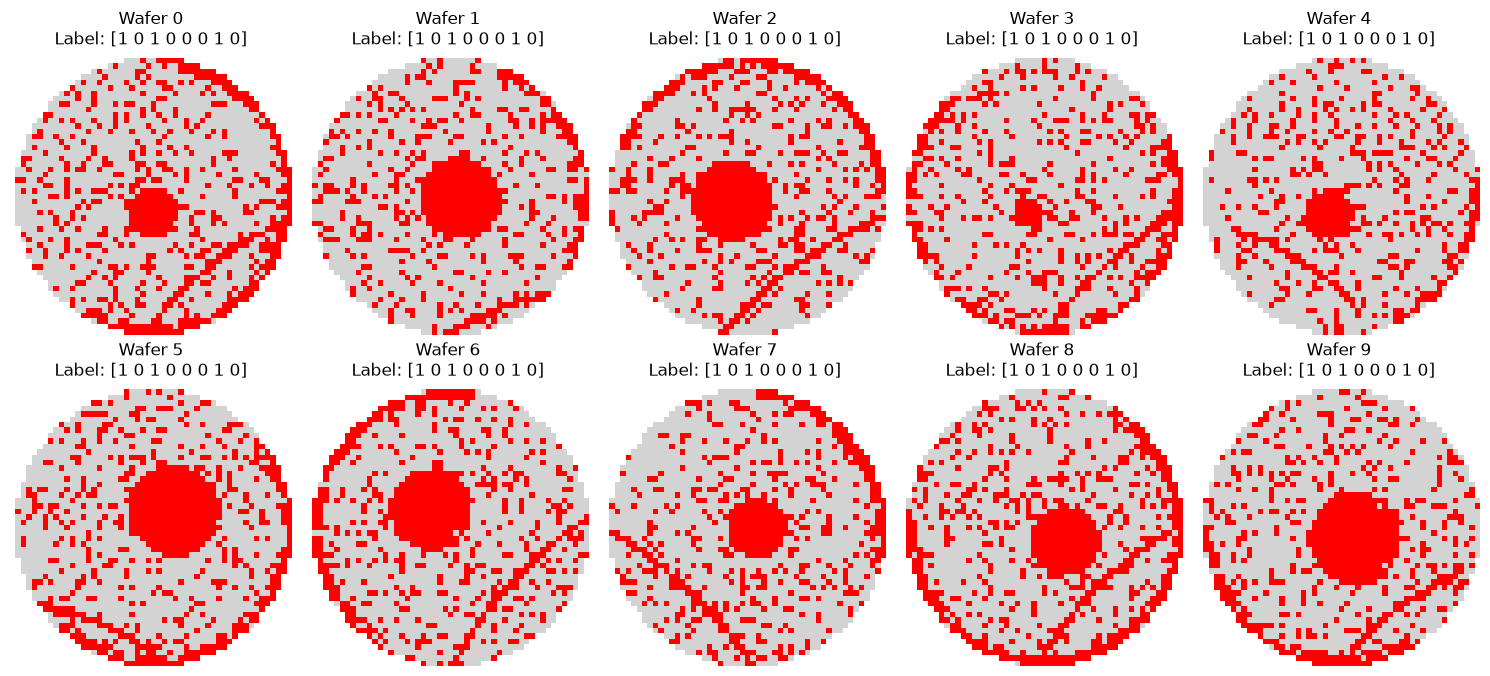

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from matplotlib.colors import ListedColormap

# 첫 번째 Row Group 불러오기
parquet_file = pq.ParquetFile(file_path)

table = parquet_file.read_row_group(
    0,
    columns=["image", "label"]
)

df = table.to_pandas()

print("불러온 데이터 개수:", len(df))
print("컬럼:", df.columns.tolist())

# Wafer Map을 2차원 정수 배열로 변환
def convert_wafer(image):
    return np.stack(image).astype(np.int32)

wafer = convert_wafer(df.iloc[0]["image"])

print("\n첫 번째 Wafer Map 크기:", wafer.shape)
print("Die 상태 값:", np.unique(wafer))
print("첫 번째 라벨:", df.iloc[0]["label"])

# 10개 Wafer Map 시각화
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

cmap = ListedColormap([
    "white",       # 0: Die 없음
    "lightgray",   # 1: 정상 Die
    "red"          # 2: 불량 Die
])

for i, ax in enumerate(axes.flat):
    wafer = convert_wafer(df.iloc[i]["image"])
    label = df.iloc[i]["label"]

    ax.imshow(
        wafer,
        cmap=cmap,
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )

    ax.set_title(f"Wafer {i}\nLabel: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import pandas as pd

# 첫 번째 Row Group의 라벨을 2차원 배열로 변환
labels = np.stack(df["label"].to_numpy()).astype(int)

print("라벨 배열 크기:", labels.shape)
print("라벨 차원 수:", labels.shape[1])

# 각 라벨별 출현 횟수
label_counts = labels.sum(axis=0)

print("\n라벨별 출현 횟수:")
for i, count in enumerate(label_counts):
    print(f"Label {i}: {count}")

# 웨이퍼당 결함 라벨 개수
num_defects = labels.sum(axis=1)

print("\n웨이퍼당 라벨 개수 분포:")
print(pd.Series(num_defects).value_counts().sort_index())

# 라벨 조합별 빈도
label_combinations = pd.Series([
    tuple(row) for row in labels
])

print("\n상위 10개 라벨 조합:")
print(label_combinations.value_counts().head(10))

라벨 배열 크기: (1000, 8)
라벨 차원 수: 8

라벨별 출현 횟수:
Label 0: 1000
Label 1: 0
Label 2: 1000
Label 3: 0
Label 4: 0
Label 5: 0
Label 6: 1000
Label 7: 0

웨이퍼당 라벨 개수 분포:
3    1000
Name: count, dtype: int64

상위 10개 라벨 조합:
(1, 0, 1, 0, 0, 0, 1, 0)    1000
Name: count, dtype: int64


In [6]:

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# 기존 다운로드 파일 사용
parquet_file = pq.ParquetFile(file_path)

# 이미지 제외, 라벨만 읽기
label_table = parquet_file.read(columns=["label"])

all_labels = np.stack(
    label_table.column("label").to_pylist()
).astype(int)

print("전체 라벨 배열:", all_labels.shape)

# 라벨별 출현 빈도
print("\n라벨별 출현 횟수:")
for i, count in enumerate(all_labels.sum(axis=0)):
    print(f"Label {i}: {count}")

# 웨이퍼당 결함 개수
print("\n웨이퍼당 결함 개수:")
print(
    pd.Series(all_labels.sum(axis=1))
    .value_counts()
    .sort_index()
)

# 서로 다른 라벨 조합
combinations = pd.Series([
    tuple(row) for row in all_labels
])

print("\n고유 라벨 조합 수:", combinations.nunique())

print("\n상위 15개 라벨 조합:")
print(combinations.value_counts().head(15))


전체 라벨 배열: (19008, 8)

라벨별 출현 횟수:
Label 0: 13000
Label 1: 6008
Label 2: 9000
Label 3: 6008
Label 4: 8008
Label 5: 0
Label 6: 10008
Label 7: 0

웨이퍼당 결함 개수:
1    1000
2    6000
3    9000
4    3008
Name: count, dtype: int64

고유 라벨 조합 수: 19

상위 15개 라벨 조합:
(1, 0, 1, 0, 0, 0, 1, 0)    2000
(1, 0, 1, 0, 0, 0, 0, 0)    1000
(1, 0, 0, 1, 0, 0, 1, 0)    1000
(1, 0, 0, 1, 0, 0, 0, 0)    1000
(1, 0, 1, 0, 1, 0, 1, 0)    1000
(1, 0, 1, 0, 1, 0, 0, 0)    1000
(1, 0, 0, 1, 1, 0, 1, 0)    1000
(1, 0, 0, 1, 1, 0, 0, 0)    1000
(1, 0, 0, 0, 1, 0, 1, 0)    1000
(1, 0, 0, 0, 1, 0, 0, 0)    1000
(1, 0, 0, 0, 0, 0, 1, 0)    1000
(1, 0, 0, 0, 0, 0, 0, 0)    1000
(0, 1, 1, 0, 0, 0, 1, 0)    1000
(0, 1, 1, 0, 0, 0, 0, 0)    1000
(0, 1, 0, 1, 0, 0, 1, 0)    1000
Name: count, dtype: int64


In [7]:
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq
import numpy as np
import pandas as pd

dataset_id = "oliversinn/waferguard-dataset"

# 두 번째 Parquet 파일 다운로드
file_path_2 = hf_hub_download(
    repo_id=dataset_id,
    filename="data/train-00001-of-00002.parquet",
    repo_type="dataset"
)

# 첫 번째 파일은 기존 file_path 재사용
paths = [file_path, file_path_2]

all_label_parts = []

for path in paths:
    pf = pq.ParquetFile(path)

    labels = np.asarray(
        pf.read(columns=["label"]).column("label").to_pylist(),
        dtype=np.int32
    )

    print("파일:", path.split("\\")[-1])
    print("웨이퍼 수:", len(labels))
    print("라벨 차원:", labels.shape[1])
    print("라벨별 개수:", labels.sum(axis=0))
    print()

    all_label_parts.append(labels)

# 전체 라벨 결합
labels_total = np.concatenate(all_label_parts, axis=0)

print("전체 웨이퍼 수:", len(labels_total))
print("전체 라벨별 개수:", labels_total.sum(axis=0))

# 고유 라벨 조합
unique_labels, counts = np.unique(
    labels_total,
    axis=0,
    return_counts=True
)

print("전체 고유 라벨 조합:", len(unique_labels))

print("\n웨이퍼당 결함 수:")
print(
    pd.Series(labels_total.sum(axis=1))
    .value_counts()
    .sort_index()
)

파일: train-00000-of-00002.parquet
웨이퍼 수: 19008
라벨 차원: 8
라벨별 개수: [13000  6008  9000  6008  8008     0 10008     0]

파일: train-00001-of-00002.parquet
웨이퍼 수: 19007
라벨 차원: 8
라벨별 개수: [   0 5992 4000 5992 9992  149 8992  866]

전체 웨이퍼 수: 38015
전체 라벨별 개수: [13000 12000 13000 12000 18000   149 19000   866]
전체 고유 라벨 조합: 38

웨이퍼당 결함 수:
0     1000
1     7015
2    13000
3    13000
4     4000
Name: count, dtype: int64


In [8]:
from huggingface_hub import hf_hub_download
from pathlib import Path

readme_path = hf_hub_download(
    repo_id="oliversinn/waferguard-dataset",
    filename="README.md",
    repo_type="dataset"
)

readme = Path(readme_path).read_text(encoding="utf-8")

print(readme[:12000])

---
dataset_info:
  features:
  - name: image
    sequence:
    - sequence:
      - dtype: int64
  - name: label
    sequence:
    - dtype: int64
  splits:
  - name: train
    num_examples: 38000
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
license: cc-by-4.0
tags:
- semiconductor-manufacturing
- wafer-defect
- defect-pattern-recognition
- image-classification
- mixed-type-defect
size_categories:
- 10k<n<100k
source_datasets:
- https://www.kaggle.com/datasets/qingyi/wafer-map-defect
language:
- en
---

# Wafer Map Defect Dataset (Mixed-Type)

## Dataset Summary

This is a comprehensive mixed-type wafer map defect dataset containing **38,000 samples** for defect pattern recognition (DPR) in semiconductor wafer manufacturing. The dataset combines real wafer map data with synthetically augmented samples generated using generative adversarial networks (GANs) to ensure balanced representation across all 38 defect pattern classes.

## Overview

Wafer 

In [9]:
from huggingface_hub import hf_hub_download
import numpy as np

# 현재 확인된 라벨 구조
print("WaferGuard label shape:", labels_total.shape)

# 라벨별 단독 샘플 개수
single_mask = labels_total.sum(axis=1) == 1
single_labels = labels_total[single_mask]

print("\n단일 결함 샘플:")
for i in range(8):
    count = np.sum(single_labels[:, i] == 1)
    print(f"Label {i}: {count}개")

WaferGuard label shape: (38015, 8)

단일 결함 샘플:
Label 0: 1000개
Label 1: 1000개
Label 2: 1000개
Label 3: 1000개
Label 4: 1000개
Label 5: 149개
Label 6: 1000개
Label 7: 866개


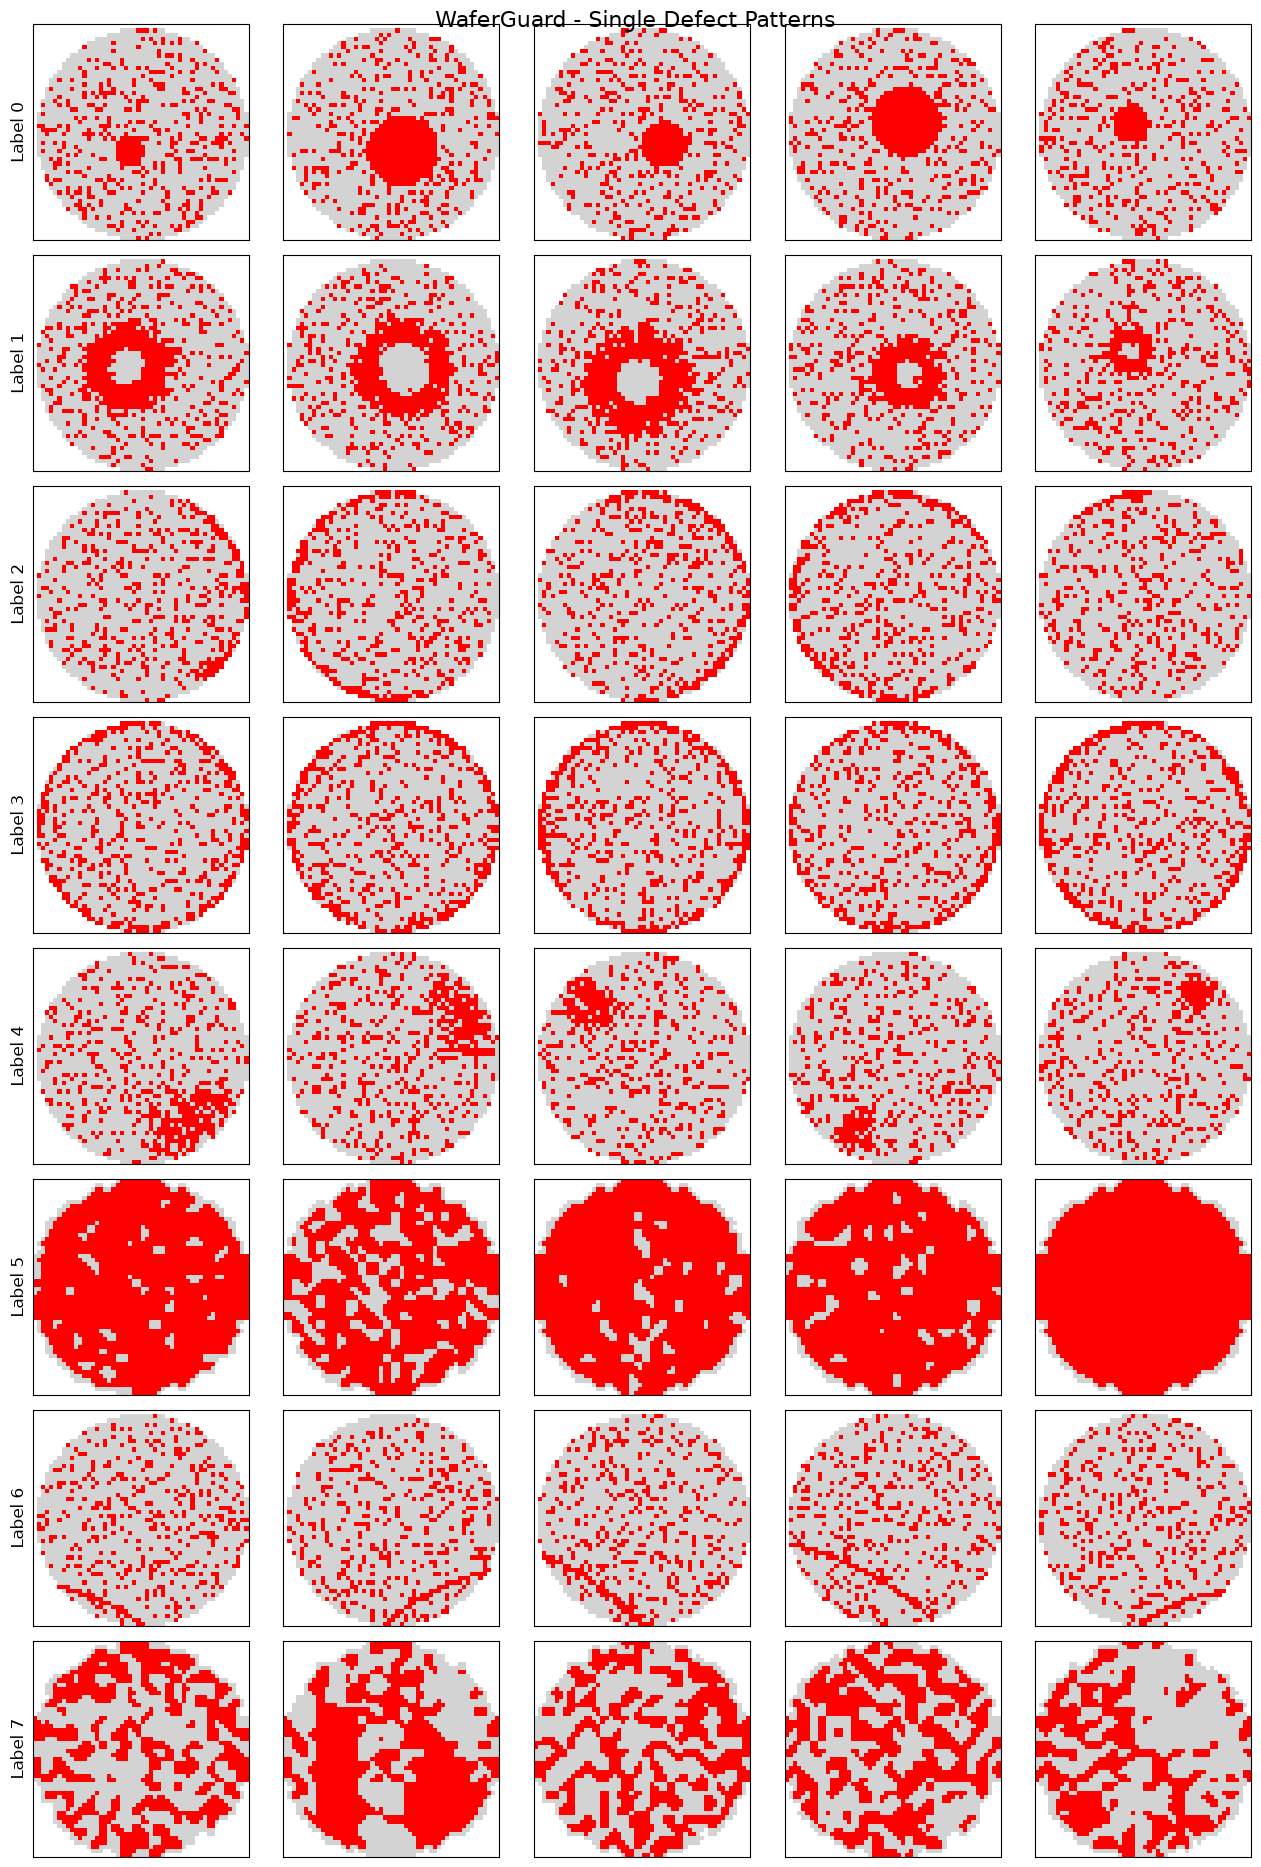

수집된 샘플 개수:
Label 0: 5
Label 1: 5
Label 2: 5
Label 3: 5
Label 4: 5
Label 5: 5
Label 6: 5
Label 7: 5


In [10]:

import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from matplotlib.colors import ListedColormap

# 앞에서 다운로드한 두 파일 사용
paths = [file_path, file_path_2]

# 라벨별 단일 결함 샘플 5개 수집
samples = {i: [] for i in range(8)}

for path in paths:
    pf = pq.ParquetFile(path)

    for rg in range(pf.num_row_groups):
        # 해당 Row Group의 라벨만 먼저 확인
        label_table = pf.read_row_group(
            rg, columns=["label"]
        )

        labels = np.asarray(
            label_table.column("label").to_pylist(),
            dtype=np.int32
        )

        # 아직 5개를 모으지 못한 라벨의 샘플 인덱스
        selected = {}

        for i in range(8):
            needed = 5 - len(samples[i])

            if needed <= 0:
                continue

            idx = np.where(
                (labels[:, i] == 1) &
                (labels.sum(axis=1) == 1)
            )[0][:needed]

            if len(idx) > 0:
                selected[i] = idx

        if not selected:
            continue

        # 필요한 Row Group에서 이미지 읽기
        image_table = pf.read_row_group(
            rg, columns=["image"]
        )

        images = image_table.column("image").to_pylist()

        for i, indices in selected.items():
            for idx in indices:
                wafer = np.asarray(
                    images[idx],
                    dtype=np.int32
                )

                samples[i].append(wafer)

    if all(len(samples[i]) >= 5 for i in range(8)):
        break

# 시각화
cmap = ListedColormap([
    "white",
    "lightgray",
    "red"
])

fig, axes = plt.subplots(
    8, 5, figsize=(13, 19)
)

for i in range(8):
    for j in range(5):
        ax = axes[i, j]

        if j < len(samples[i]):
            ax.imshow(
                samples[i][j],
                cmap=cmap,
                vmin=0,
                vmax=2,
                interpolation="nearest"
            )

        if j == 0:
            ax.set_ylabel(
                f"Label {i}",
                fontsize=12,
                rotation=90
            )

        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle(
    "WaferGuard - Single Defect Patterns",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("수집된 샘플 개수:")
for i in range(8):
    print(f"Label {i}: {len(samples[i])}")


In [12]:
import numpy as np
import pyarrow.parquet as pq

X_parts = []
y_parts = []

for path in [file_path, file_path_2]:
    pf = pq.ParquetFile(path)

    for rg in range(pf.num_row_groups):
        table = pf.read_row_group(
            rg, columns=["image", "label"]
        )

        images = np.asarray(
            table.column("image").to_pylist(),
            dtype=np.uint8
        )

        labels = np.asarray(
            table.column("label").to_pylist(),
            dtype=np.uint8
        )

        X_parts.append(images)
        y_parts.append(labels)

X_wafer = np.concatenate(X_parts, axis=0)
y_wafer = np.concatenate(y_parts, axis=0)

del X_parts, y_parts

print("X_wafer shape:", X_wafer.shape)
print("y_wafer shape:", y_wafer.shape)

print("이미지 데이터 타입:", X_wafer.dtype)
print("라벨 데이터 타입:", y_wafer.dtype)

print("이미지 값:", np.unique(X_wafer))
print("전체 메모리:", round(X_wafer.nbytes / 1024**2, 2), "MB")

X_wafer shape: (38015, 52, 52)
y_wafer shape: (38015, 8)
이미지 데이터 타입: uint8
라벨 데이터 타입: uint8
이미지 값: [0 1 2 3]
전체 메모리: 98.03 MB


전체 픽셀값 분포:
Pixel 0: 24,349,490개 (23.6880%)
Pixel 1: 53,392,308개 (51.9418%)
Pixel 2: 25,050,548개 (24.3700%)
Pixel 3: 214개 (0.0002%)

픽셀값 3이 포함된 웨이퍼: 105
전체 웨이퍼 대비 비율: 0.28 %


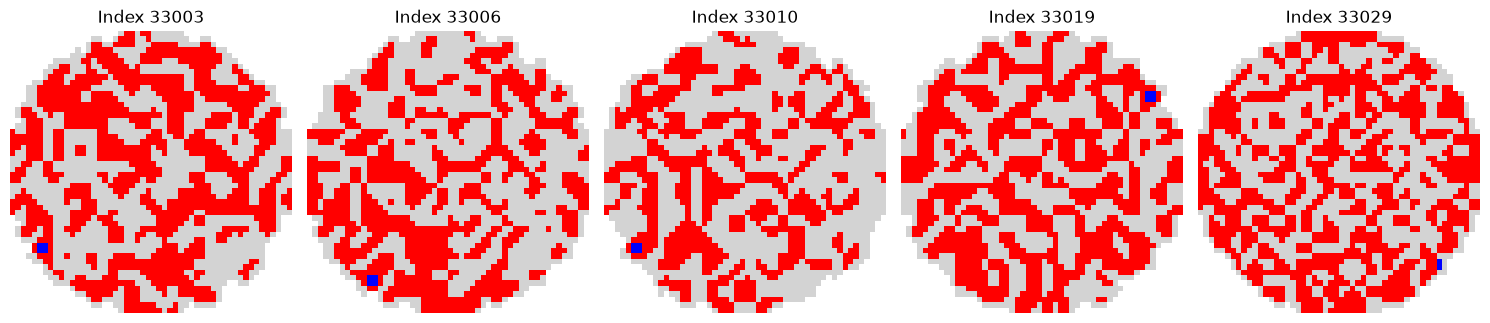

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 전체 픽셀값 분포
values, counts = np.unique(X_wafer, return_counts=True)

print("전체 픽셀값 분포:")
for value, count in zip(values, counts):
    print(f"Pixel {value}: {count:,}개 ({count / X_wafer.size * 100:.4f}%)")

# 픽셀값 3이 포함된 웨이퍼 찾기
has_3 = np.any(X_wafer == 3, axis=(1, 2))
indices_3 = np.where(has_3)[0]

print("\n픽셀값 3이 포함된 웨이퍼:", len(indices_3))
print("전체 웨이퍼 대비 비율:", round(has_3.mean() * 100, 2), "%")

# 픽셀값 3이 있는 웨이퍼 5개 시각화
if len(indices_3) > 0:
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

    cmap = ListedColormap([
        "white", "lightgray", "red", "blue"
    ])

    for ax, idx in zip(axes, indices_3[:5]):
        ax.imshow(
            X_wafer[idx],
            cmap=cmap,
            vmin=0,
            vmax=3,
            interpolation="nearest"
        )
        ax.set_title(f"Index {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

Wafer Index: 33003
Wafer Label: [0 0 0 0 0 0 0 1]
픽셀값 3의 개수: 4
픽셀값 3의 좌표: [[39, 5], [39, 6], [40, 5], [40, 6]]


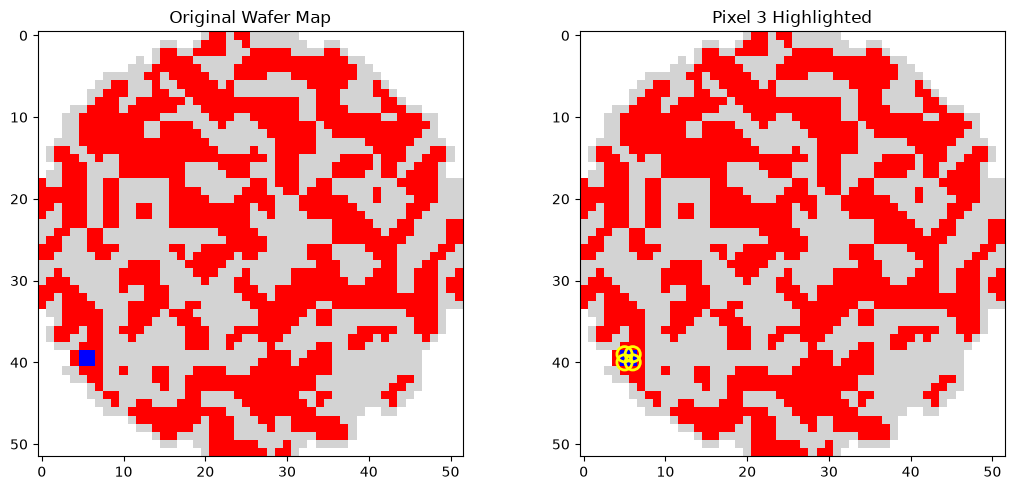

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 픽셀값 3이 포함된 첫 번째 웨이퍼
idx = indices_3[0]
wafer = X_wafer[idx]

# 픽셀값 3의 좌표
positions = np.argwhere(wafer == 3)

print("Wafer Index:", idx)
print("Wafer Label:", y_wafer[idx])
print("픽셀값 3의 개수:", len(positions))
print("픽셀값 3의 좌표:", positions.tolist())

# 시각화
cmap = ListedColormap(["white", "lightgray", "red", "blue"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(wafer, cmap=cmap, vmin=0, vmax=3,
               interpolation="nearest")
axes[0].set_title("Original Wafer Map")

axes[1].imshow(wafer, cmap=cmap, vmin=0, vmax=3,
               interpolation="nearest")

for row, col in positions:
    axes[1].scatter(col, row, s=120, facecolors="none",
                    edgecolors="yellow", linewidths=2)

axes[1].set_title("Pixel 3 Highlighted")

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
from sklearn.model_selection import train_test_split

# 원본 X_wafer는 보존
X_clean = X_wafer.copy()

# 미정의 픽셀값 3을 임시로 불량 Die(2)로 처리
X_clean[X_clean == 3] = 2

# 각 8차원 라벨 조합을 하나의 문자열로 변환
# 38개 조합별 층화 분할을 위한 용도
combo_labels = np.array([
    "".join(map(str, row))
    for row in y_wafer
])

# Train 80%, 임시 데이터 20%
X_train, X_temp, y_train, y_temp, combo_train, combo_temp = train_test_split(
    X_clean,
    y_wafer,
    combo_labels,
    test_size=0.2,
    random_state=42,
    stratify=combo_labels
)

# Validation 10%, Test 10%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=combo_temp
)

# CNN 입력: 0~1 정규화 + 채널 차원 추가
X_train = (X_train.astype(np.float32) / 2.0)[..., np.newaxis]
X_val   = (X_val.astype(np.float32) / 2.0)[..., np.newaxis]
X_test  = (X_test.astype(np.float32) / 2.0)[..., np.newaxis]

# Multi-label 학습을 위한 float32 변환
y_train = y_train.astype(np.float32)
y_val = y_val.astype(np.float32)
y_test = y_test.astype(np.float32)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\n정규화 범위:", X_train.min(), "~", X_train.max())
print("Train 라벨 조합 수:", len(np.unique(
    ["".join(map(str, row.astype(int))) for row in y_train]
)))

Train: (30412, 52, 52, 1) (30412, 8)
Validation: (3801, 52, 52, 1) (3801, 8)
Test: (3802, 52, 52, 1) (3802, 8)

정규화 범위: 0.0 ~ 1.0
Train 라벨 조합 수: 38


In [16]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(52, 52, 1)),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),

    # Classification Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(8, activation="sigmoid")
], name="WaferGuard_CNN")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        tf.keras.metrics.AUC(name="auc", multi_label=True)
    ]
)

model.summary()


Model: "WaferGuard_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 52, 52, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 52, 52, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 52, 52, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 13, 13, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,872 (1.16 MB)

 Trainable params: 304,424 (1.16 MB)

 Non-trainable params: 448 (1.75 KB)

In [17]:

import tensorflow as tf
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# 학습 중 가장 좋은 모델 저장
checkpoint = ModelCheckpoint(
    "waferguard_pretrained.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Validation Loss 개선이 없으면 조기 종료
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Validation Loss가 정체되면 학습률 감소
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    mode="min",
    verbose=1
)

# WaferGuard CNN 사전학습
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)


Epoch 1/20
475/476 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - auc: 0.9767 - binary_accuracy: 0.9473 - loss: 0.1275
Epoch 1: val_loss improved from None to 2.31627, saving model to waferguard_pretrained.keras

Epoch 1: finished saving model to waferguard_pretrained.keras
476/476 ━━━━━━━━━━━━━━━━━━━━ 68s 136ms/step - auc: 0.9767 - binary_accuracy: 0.9473 - loss: 0.1275 - val_auc: 0.6109 - val_binary_accuracy: 0.7123 - val_loss: 2.3163 - learning_rate: 0.0010
Epoch 2/20
475/476 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - auc: 0.9954 - binary_accuracy: 0.9894 - loss: 0.0377
Epoch 2: val_loss improved from 2.31627 to 0.08713, saving model to waferguard_pretrained.keras

Epoch 2: finished saving model to waferguard_pretrained.keras
476/476 ━━━━━━━━━━━━━━━━━━━━ 66s 138ms/step - auc: 0.9954 - binary_accuracy: 0.9894 - loss: 0.0376 - val_auc: 0.9917 - val_binary_accuracy: 0.9738 - val_loss: 0.0871 - learning_rate: 0.0010
Epoch 3/20
475/476 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - auc: 0.9972 - binary_accuracy: 

In [18]:

import numpy as np
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

# 최적 모델 불러오기
best_model = tf.keras.models.load_model(
    "waferguard_pretrained.keras"
)

# Test 데이터 평가
results = best_model.evaluate(
    X_test, y_test,
    batch_size=64,
    verbose=1,
    return_dict=True
)

print("\n=== Test 평가 결과 ===")
for name, value in results.items():
    print(f"{name}: {value:.4f}")

# 라벨별 예측 확률
y_prob = best_model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

# 우선 임계값 0.5 사용
y_pred = (y_prob >= 0.5).astype(int)
y_true = y_test.astype(int)

# 라벨별 분류 성능
print("\n=== Label별 성능 ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=[f"Label {i}" for i in range(8)],
    zero_division=0
))

# 웨이퍼의 모든 라벨을 정확하게 예측했는지
exact_match = accuracy_score(y_true, y_pred)

print(f"Exact Match Accuracy: {exact_match:.4f}")

# 전체 라벨 기준 Macro F1
macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Macro F1 Score: {macro_f1:.4f}")


60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - auc: 0.9989 - binary_accuracy: 0.9969 - loss: 0.0130

=== Test 평가 결과 ===
auc: 0.9989
binary_accuracy: 0.9969
loss: 0.0130

=== Label별 성능 ===
              precision    recall  f1-score   support

     Label 0       1.00      1.00      1.00      1300
     Label 1       1.00      1.00      1.00      1200
     Label 2       0.99      0.98      0.99      1300
     Label 3       0.99      0.99      0.99      1200
     Label 4       1.00      0.99      0.99      1800
     Label 5       1.00      1.00      1.00        15
     Label 6       0.99      0.99      0.99      1900
     Label 7       1.00      1.00      1.00        87

   micro avg       1.00      0.99      0.99      8802
   macro avg       1.00      0.99      1.00      8802
weighted avg       1.00      0.99      0.99      8802
 samples avg       0.97      0.97      0.97      8802

Exact Match Accuracy: 0.9792
Macro F1 Score: 0.9960


In [19]:
import tensorflow as tf

# 저장된 최적 WaferGuard 모델 불러오기
pretrained_model = tf.keras.models.load_model(
    "waferguard_pretrained.keras"
)

# GlobalAveragePooling2D 직전까지의 CNN 특징 추출층
feature_extractor = tf.keras.Model(
    inputs=pretrained_model.inputs,
    outputs=pretrained_model.get_layer(
        "global_average_pooling2d"
    ).output,
    name="WaferGuard_Feature_Extractor"
)

# 처음에는 사전학습된 특징 추출층을 고정
feature_extractor.trainable = False

print("Feature Extractor Input:", feature_extractor.input_shape)
print("Feature Extractor Output:", feature_extractor.output_shape)
print("Trainable:", feature_extractor.trainable)

feature_extractor.summary()

Feature Extractor Input: (None, 52, 52, 1)
Feature Extractor Output: (None, 128)
Trainable: False


Model: "WaferGuard_Feature_Extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 52, 52, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 52, 52, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 52, 52, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 52, 52, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 13, 13, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 287,328 (1.10 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 287,328 (1.10 MB)

In [20]:

import numpy as np

# 기존 Notebook에 존재하는 데이터 변수 확인
candidate_names = [
    "X", "y",
    "X_train", "X_test", "X_val",
    "y_train", "y_test", "y_val",
    "x_train", "x_test",
    "train_images", "test_images",
    "train_labels", "test_labels",
    "df", "data", "model"
]

print("=== 기존 WM-811K 변수 확인 ===")

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}, type={type(obj).__name__}")
        else:
            print(f"{name}: type={type(obj).__name__}")

# 기존 모델이 있다면 입력/출력 크기 확인
if "model" in globals():
    try:
        print("\n기존 모델 입력:", model.input_shape)
        print("기존 모델 출력:", model.output_shape)
    except Exception as e:
        print("모델 정보 확인 불가:", e)


=== 기존 WM-811K 변수 확인 ===
X_train: shape=(30412, 52, 52, 1), type=ndarray
X_test: shape=(3802, 52, 52, 1), type=ndarray
X_val: shape=(3801, 52, 52, 1), type=ndarray
y_train: shape=(30412, 8), type=ndarray
y_test: shape=(3802, 8), type=ndarray
y_val: shape=(3801, 8), type=ndarray
df: shape=(1000, 2), type=DataFrame
model: type=Sequential

기존 모델 입력: (None, 52, 52, 1)
기존 모델 출력: (None, 8)


In [21]:
from pathlib import Path

print("현재 작업 폴더:")
print(Path.cwd())

print("\nWM-811K 관련 파일 검색:")

search_roots = [
    Path.cwd(),
    Path.home() / "Downloads",
    Path.home() / "Desktop",
    Path.home() / "Documents"
]

found = set()

for root in search_roots:
    if not root.exists():
        continue

    try:
        for path in root.rglob("*"):
            if path.is_file() and (
                "wm811k" in path.name.lower()
                or "wm-811k" in path.name.lower()
            ):
                if str(path) not in found:
                    print(path)
                    found.add(str(path))
    except (PermissionError, OSError) as e:
        print(f"검색 제한: {root} ({e})")

if not found:
    print("WM-811K 파일을 찾지 못했습니다.")

현재 작업 폴더:
C:\Users\fl27

WM-811K 관련 파일 검색:
C:\Users\fl27\WM811K.pkl
검색 제한: C:\Users\fl27 ([WinError 3] 지정된 경로를 찾을 수 없습니다: 'C:\\Users\\fl27\\AppData\\Local\\claude-cli-nodejs\\Cache\\C--Users-fl27-AppData-Roaming-Claude-local-agent-mode-sessions-56ec533c-33b1-4999-a924-beb69dae9e95-24cf2fcf-ce21-4c4f-a1b5-68efa06f84da-local-4e143669-6bf6-41fa-aad8-acf3d3922a10-outputs\\mcp-logs-workspace')
C:\Users\fl27\Desktop\데이터분석시각화\WM811K.pkl


In [22]:
import pandas as pd
from pathlib import Path

# WM-811K 원본 파일 경로
wm_path = Path(r"C:\Users\fl27\WM811K.pkl")

# 데이터 불러오기
wm_df = pd.read_pickle(wm_path)

print("=== WM-811K 데이터셋 ===")
print("전체 데이터 크기:", wm_df.shape)

print("\n컬럼 목록:")
print(wm_df.columns.tolist())

print("\n데이터 타입:")
print(wm_df.dtypes)

print("\n첫 번째 데이터:")
print(wm_df.iloc[0])

# 결함 라벨 분포 확인
if "failureType" in wm_df.columns:
    print("\n=== 결함 라벨 분포 ===")

    failure_labels = wm_df["failureType"].apply(
        lambda x: str(x[0]) if hasattr(x, "__len__") and len(x) > 0 else "Empty"
    )

    print(failure_labels.value_counts())

=== WM-811K 데이터셋 ===
전체 데이터 크기: (811457, 6)

컬럼 목록:
['dieSize', 'failureType', 'lotName', 'trainTestLabel', 'waferIndex', 'waferMap']

데이터 타입:
dieSize           float64
failureType        object
lotName            object
trainTestLabel     object
waferIndex        float64
waferMap           object
dtype: object

첫 번째 데이터:
dieSize                                                      1683.0
failureType                                                    none
lotName                                                        lot1
trainTestLabel                                             Training
waferIndex                                                      1.0
waferMap          [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...
Name: 0, dtype: object

=== 결함 라벨 분포 ===
failureType
0    638507
n    147431
E     14869
C      4294
L      3593
S      1193
R       866
D       555
N       149
Name: count, dtype: int64


In [23]:

import pandas as pd
import numpy as np

# 문자열과 배열 형태를 모두 처리
def extract_label(x):
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 0:
            return "Unlabeled"
        return str(x[0]).strip()
    return str(x).strip()

# 원본 데이터는 유지하고 새 컬럼 생성
wm_df["failure_label"] = wm_df["failureType"].apply(
    extract_label
)

wm_df["split_label"] = wm_df["trainTestLabel"].apply(
    extract_label
)

print("=== 실제 결함 라벨 분포 ===")
print(wm_df["failure_label"].value_counts())

print("\n=== Train/Test 구분 ===")
print(wm_df["split_label"].value_counts())

print("\n=== 결함별 Train/Test 분포 ===")
print(pd.crosstab(
    wm_df["failure_label"],
    wm_df["split_label"]
))


=== 실제 결함 라벨 분포 ===
failure_label
0            638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

=== Train/Test 구분 ===
split_label
0           638507
Test        118595
Training     54355
Name: count, dtype: int64

=== 결함별 Train/Test 분포 ===
split_label         0    Test  Training
failure_label                          
0              638507       0         0
Center              0     832      3462
Donut               0     146       409
Edge-Loc            0    2772      2417
Edge-Ring           0    1126      8554
Loc                 0    1973      1620
Near-full           0      95        54
Random              0     257       609
Scratch             0     693       500
none                0  110701     36730


In [24]:

import numpy as np
import pandas as pd

# WM-811K 8개 결함 클래스
wm_classes = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch"
]

# 결함 라벨이 있는 데이터만 추출
wm_defect_df = wm_df[
    wm_df["failure_label"].isin(wm_classes)
].copy()

# 클래스별 숫자 인코딩
wm_label_map = {
    name: idx
    for idx, name in enumerate(wm_classes)
}

wm_defect_df["class_id"] = (
    wm_defect_df["failure_label"]
    .map(wm_label_map)
    .astype(np.int32)
)

print("=== WM-811K 결함 데이터 ===")
print("전체 결함 웨이퍼:", len(wm_defect_df))

print("\n클래스 매핑:")
for name, idx in wm_label_map.items():
    print(f"{idx}: {name}")

print("\nTrain/Test 분포:")
print(wm_defect_df["split_label"].value_counts())

print("\n클래스별 데이터:")
print(
    pd.crosstab(
        wm_defect_df["failure_label"],
        wm_defect_df["split_label"]
    ).reindex(wm_classes)
)

# 이미지 크기 분포 확인
wm_defect_df["map_shape"] = wm_defect_df["waferMap"].apply(
    lambda x: tuple(np.asarray(x).shape)
)

print("\n이미지 크기 종류:", wm_defect_df["map_shape"].nunique())

print("\n가장 흔한 이미지 크기 10개:")
print(wm_defect_df["map_shape"].value_counts().head(10))


=== WM-811K 결함 데이터 ===
전체 결함 웨이퍼: 25519

클래스 매핑:
0: Center
1: Donut
2: Edge-Loc
3: Edge-Ring
4: Loc
5: Near-full
6: Random
7: Scratch

Train/Test 분포:
split_label
Training    17625
Test         7894
Name: count, dtype: int64

클래스별 데이터:
split_label    Test  Training
failure_label                
Center          832      3462
Donut           146       409
Edge-Loc       2772      2417
Edge-Ring      1126      8554
Loc            1973      1620
Near-full        95        54
Random          257       609
Scratch         693       500

이미지 크기 종류: 329

가장 흔한 이미지 크기 10개:
map_shape
(25, 27)    2900
(38, 36)    2127
(53, 52)    1519
(63, 62)    1424
(39, 37)    1015
(26, 26)     877
(30, 34)     710
(35, 31)     648
(44, 41)     600
(29, 26)     555
Name: count, dtype: int64


In [25]:

import numpy as np
import tensorflow as tf

# WM-811K 이미지를 52x52로 변환
def preprocess_wm_map(wafer_map):
    arr = np.asarray(wafer_map, dtype=np.float32)

    # 입력 이미지 차원: (H, W, 1)
    arr = arr[..., np.newaxis]

    # Nearest Neighbor 리사이징
    resized = tf.image.resize(
        arr,
        size=(52, 52),
        method="nearest"
    ).numpy()

    # WaferGuard와 동일하게 0~1 정규화
    return resized / 2.0

# 전체 WM-811K 결함 이미지 전처리
wm_X = np.stack([
    preprocess_wm_map(wafer_map)
    for wafer_map in wm_defect_df["waferMap"]
]).astype(np.float32)

# 숫자 라벨
wm_y = wm_defect_df["class_id"].to_numpy(
    dtype=np.int32
)

# 원본 Training/Test 구분
wm_split = wm_defect_df["split_label"].to_numpy()

print("=== WM-811K 전처리 결과 ===")
print("X shape:", wm_X.shape)
print("y shape:", wm_y.shape)

print("\n픽셀 값 범위:")
print("Min:", wm_X.min())
print("Max:", wm_X.max())

print("\n변환 후 픽셀 값:")
print(np.unique(wm_X))

print("\nTraining:", np.sum(wm_split == "Training"))
print("Test:", np.sum(wm_split == "Test"))


=== WM-811K 전처리 결과 ===
X shape: (25519, 52, 52, 1)
y shape: (25519,)

픽셀 값 범위:
Min: 0.0
Max: 1.0

변환 후 픽셀 값:
[0.  0.5 1. ]

Training: 17625
Test: 7894


In [26]:

from sklearn.model_selection import train_test_split
import numpy as np

# 원본 WM-811K Train/Test 구분 유지
train_mask = (wm_split == "Training")
test_mask = (wm_split == "Test")

wm_X_train_all = wm_X[train_mask]
wm_y_train_all = wm_y[train_mask]

wm_X_test = wm_X[test_mask]
wm_y_test = wm_y[test_mask]

# Training 데이터에서 Validation 20% 분리
wm_X_train, wm_X_val, wm_y_train, wm_y_val = train_test_split(
    wm_X_train_all,
    wm_y_train_all,
    test_size=0.2,
    random_state=42,
    stratify=wm_y_train_all
)

print("=== WM-811K 데이터 분할 ===")
print("Train:", wm_X_train.shape, wm_y_train.shape)
print("Validation:", wm_X_val.shape, wm_y_val.shape)
print("Test:", wm_X_test.shape, wm_y_test.shape)

print("\n=== 클래스별 데이터 개수 ===")

print(f"{'Class':<12} {'Train':>8} {'Val':>8} {'Test':>8}")
print("-" * 40)

for idx, name in enumerate(wm_classes):
    train_count = np.sum(wm_y_train == idx)
    val_count = np.sum(wm_y_val == idx)
    test_count = np.sum(wm_y_test == idx)

    print(
        f"{name:<12} "
        f"{train_count:>8} "
        f"{val_count:>8} "
        f"{test_count:>8}"
    )


=== WM-811K 데이터 분할 ===
Train: (14100, 52, 52, 1) (14100,)
Validation: (3525, 52, 52, 1) (3525,)
Test: (7894, 52, 52, 1) (7894,)

=== 클래스별 데이터 개수 ===
Class           Train      Val     Test
----------------------------------------
Center           2770      692      832
Donut             327       82      146
Edge-Loc         1934      483     2772
Edge-Ring        6843     1711     1126
Loc              1296      324     1973
Near-full          43       11       95
Random            487      122      257
Scratch           400      100      693


In [27]:

import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# 사전학습 모델 다시 불러오기
wm_pretrained = tf.keras.models.load_model(
    "waferguard_pretrained.keras"
)

# GlobalAveragePooling2D까지 특징 추출
wm_feature_extractor = Model(
    inputs=wm_pretrained.inputs,
    outputs=wm_pretrained.get_layer(
        "global_average_pooling2d"
    ).output,
    name="WaferGuard_Feature_Extractor"
)

# 1단계: 사전학습 가중치 고정
wm_feature_extractor.trainable = False

# WM-811K 전이학습 모델
wm_inputs = layers.Input(shape=(52, 52, 1))

x = wm_feature_extractor(
    wm_inputs,
    training=False
)

x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)

wm_outputs = layers.Dense(
    8,
    activation="softmax"
)(x)

wm_transfer_model = Model(
    inputs=wm_inputs,
    outputs=wm_outputs,
    name="WM811K_Transfer_CNN"
)

wm_transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=== WM-811K Transfer Model ===")
wm_transfer_model.summary()

print("\nFeature Extractor Trainable:",
      wm_feature_extractor.trainable)

print("Model Input:", wm_transfer_model.input_shape)
print("Model Output:", wm_transfer_model.output_shape)


=== WM-811K Transfer Model ===


Model: "WM811K_Transfer_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 52, 52, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ WaferGuard_Feature_Extractor    │ (None, 128)            │       287,328 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,104 (1.13 MB)

 Trainable params: 8,776 (34.28 KB)

 Non-trainable params: 287,328 (1.10 MB)


Feature Extractor Trainable: False
Model Input: (None, 52, 52, 1)
Model Output: (None, 8)


In [28]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# WM-811K 학습 데이터의 클래스별 가중치 계산
classes = np.arange(8)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=wm_y_train
)

# 극소수 클래스의 과도한 가중치 완화
sqrt_weights = np.sqrt(balanced_weights)

# 평균 가중치가 샘플 기준 약 1이 되도록 정규화
sample_counts = np.bincount(wm_y_train, minlength=8)
normalizer = np.average(
    sqrt_weights,
    weights=sample_counts
)

sqrt_weights = sqrt_weights / normalizer

wm_class_weight = {
    int(i): float(w)
    for i, w in enumerate(sqrt_weights)
}

print("=== WM-811K 클래스별 가중치 ===")
print(f"{'Class':<12} {'Count':>8} {'Weight':>10}")
print("-" * 34)

for i, name in enumerate(wm_classes):
    print(
        f"{name:<12} "
        f"{sample_counts[i]:>8} "
        f"{wm_class_weight[i]:>10.4f}"
    )


=== WM-811K 클래스별 가중치 ===
Class           Count     Weight
----------------------------------
Center           2770     0.9499
Donut             327     2.7646
Edge-Loc         1934     1.1368
Edge-Ring        6843     0.6043
Loc              1296     1.3887
Near-full          43     7.6239
Random            487     2.2654
Scratch           400     2.4997


In [29]:

import tensorflow as tf
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# 재현성을 위한 시드 설정
tf.keras.utils.set_random_seed(42)

# 학습 콜백 설정
wm_callbacks = [
    ModelCheckpoint(
        filepath="wm811k_transfer_stage1.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("=== WM-811K Stage 1 Transfer Learning ===")

wm_history_stage1 = wm_transfer_model.fit(
    wm_X_train,
    wm_y_train,

    validation_data=(
        wm_X_val,
        wm_y_val
    ),

    epochs=25,
    batch_size=64,

    class_weight=wm_class_weight,

    callbacks=wm_callbacks,
    verbose=1
)

print("\n=== Stage 1 학습 완료 ===")

best_epoch = int(
    tf.argmin(
        wm_history_stage1.history["val_loss"]
    )
) + 1

print("Best Epoch:", best_epoch)

print(
    "Best Validation Loss:",
    min(wm_history_stage1.history["val_loss"])
)

print(
    "Best Validation Accuracy:",
    max(wm_history_stage1.history["val_accuracy"])
)


=== WM-811K Stage 1 Transfer Learning ===
Epoch 1/25
219/221 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7034 - loss: 1.1415
Epoch 1: val_loss improved from None to 0.51969, saving model to wm811k_transfer_stage1.keras

Epoch 1: finished saving model to wm811k_transfer_stage1.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.7037 - loss: 1.1393 - val_accuracy: 0.8182 - val_loss: 0.5197 - learning_rate: 0.0010
Epoch 2/25
219/221 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7918 - loss: 0.7380
Epoch 2: val_loss improved from 0.51969 to 0.46666, saving model to wm811k_transfer_stage1.keras

Epoch 2: finished saving model to wm811k_transfer_stage1.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.7918 - loss: 0.7377 - val_accuracy: 0.8363 - val_loss: 0.4667 - learning_rate: 0.0010
Epoch 3/25
219/221 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8111 - loss: 0.6783
Epoch 3: val_loss improved from 0.46666 to 0.43679, saving model to wm811k_transfer_stage1.ker

=== Stage 1 Validation 평가 ===
Accuracy: 0.8817
Macro F1: 0.8002

=== 클래스별 성능 ===
              precision    recall  f1-score   support

      Center     0.8568    0.9075    0.8814       692
       Donut     0.6869    0.8293    0.7514        82
    Edge-Loc     0.7968    0.8199    0.8082       483
   Edge-Ring     0.9940    0.9725    0.9832      1711
         Loc     0.6601    0.5154    0.5789       324
   Near-full     0.9167    1.0000    0.9565        11
      Random     0.9194    0.9344    0.9268       122
     Scratch     0.4511    0.6000    0.5150       100

    accuracy                         0.8817      3525
   macro avg     0.7852    0.8224    0.8002      3525
weighted avg     0.8840    0.8817    0.8813      3525



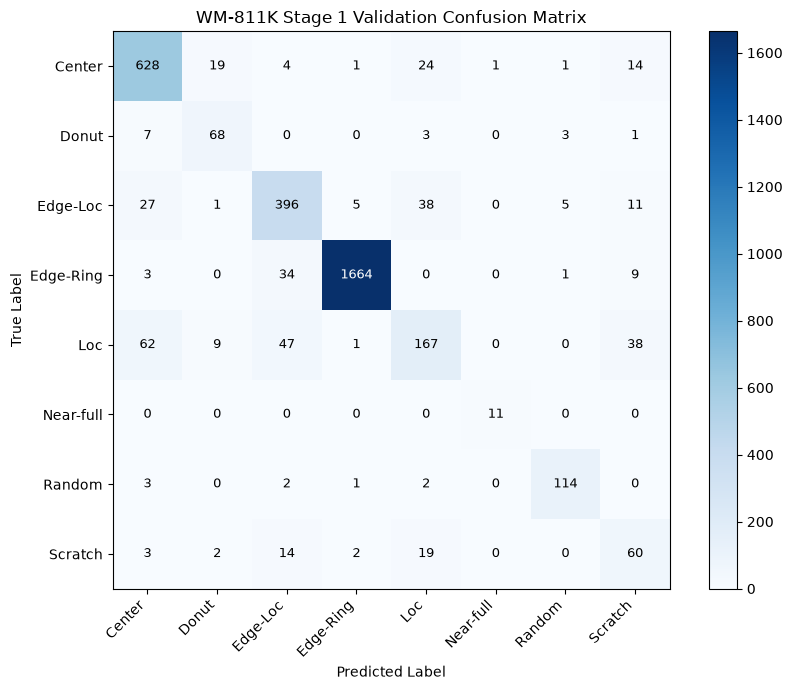

In [30]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)
import matplotlib.pyplot as plt

# Stage 1에서 Validation Loss가 가장 낮았던 모델
wm_stage1_best = tf.keras.models.load_model(
    "wm811k_transfer_stage1.keras"
)

# Validation 예측
wm_val_prob = wm_stage1_best.predict(
    wm_X_val,
    batch_size=64,
    verbose=0
)

wm_val_pred = np.argmax(wm_val_prob, axis=1)

print("=== Stage 1 Validation 평가 ===")

print(
    "Accuracy:",
    round(accuracy_score(wm_y_val, wm_val_pred), 4)
)

print(
    "Macro F1:",
    round(
        f1_score(
            wm_y_val,
            wm_val_pred,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\n=== 클래스별 성능 ===")

print(
    classification_report(
        wm_y_val,
        wm_val_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    wm_y_val,
    wm_val_pred,
    labels=np.arange(8)
)

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(8))
ax.set_yticks(range(8))

ax.set_xticklabels(wm_classes, rotation=45, ha="right")
ax.set_yticklabels(wm_classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("WM-811K Stage 1 Validation Confusion Matrix")

for i in range(8):
    for j in range(8):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=9
        )

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [31]:

import tensorflow as tf
from tensorflow.keras import layers

# Stage 1 최적 모델 불러오기
wm_stage2_model = tf.keras.models.load_model(
    "wm811k_transfer_stage1.keras"
)

# Feature Extractor 가져오기
wm_stage2_extractor = wm_stage2_model.get_layer(
    "WaferGuard_Feature_Extractor"
)

# 내부 레이어의 학습 가능 여부를 변경하기 위해 해제
wm_stage2_extractor.trainable = True

# 우선 모든 CNN 레이어 고정
for layer in wm_stage2_extractor.layers:
    layer.trainable = False

# 마지막 Conv2D 두 개만 학습 허용
conv_layers = [
    layer
    for layer in wm_stage2_extractor.layers
    if isinstance(layer, layers.Conv2D)
]

for layer in conv_layers[-2:]:
    layer.trainable = True

# BatchNormalization은 계속 고정
for layer in wm_stage2_extractor.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 낮은 학습률로 다시 컴파일
wm_stage2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=== Stage 2 Fine-tuning 설정 ===")

for layer in wm_stage2_extractor.layers:
    print(
        f"{layer.name:<28} "
        f"Trainable: {layer.trainable}"
    )

print("\n전체 모델 파라미터:")
wm_stage2_model.summary()

print("\nTrainable parameters:")
print(
    sum(
        int(tf.size(w).numpy())
        for w in wm_stage2_model.trainable_weights
    )
)


=== Stage 2 Fine-tuning 설정 ===
input_layer                  Trainable: False
conv2d                       Trainable: False
batch_normalization          Trainable: False
conv2d_1                     Trainable: False
max_pooling2d                Trainable: False
conv2d_2                     Trainable: False
batch_normalization_1        Trainable: False
conv2d_3                     Trainable: False
max_pooling2d_1              Trainable: False
conv2d_4                     Trainable: True
batch_normalization_2        Trainable: False
conv2d_5                     Trainable: True
global_average_pooling2d     Trainable: False

전체 모델 파라미터:


Model: "WM811K_Transfer_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 52, 52, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ WaferGuard_Feature_Extractor    │ (None, 128)            │       287,328 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,104 (1.13 MB)

 Trainable params: 230,216 (899.28 KB)

 Non-trainable params: 65,888 (257.38 KB)


Trainable parameters:
230216


In [32]:

import tensorflow as tf
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Stage 2 콜백
wm_stage2_callbacks = [
    ModelCheckpoint(
        "wm811k_transfer_stage2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("=== WM-811K Stage 2 Fine-tuning ===")

wm_history_stage2 = wm_stage2_model.fit(
    wm_X_train,
    wm_y_train,

    validation_data=(
        wm_X_val,
        wm_y_val
    ),

    epochs=25,
    batch_size=64,

    class_weight=wm_class_weight,

    callbacks=wm_stage2_callbacks,
    verbose=1
)

print("\n=== Stage 2 학습 완료 ===")

best_epoch = int(
    tf.argmin(
        wm_history_stage2.history["val_loss"]
    )
) + 1

print("Best Epoch:", best_epoch)

print(
    "Best Validation Loss:",
    min(wm_history_stage2.history["val_loss"])
)

print(
    "Best Validation Accuracy:",
    max(wm_history_stage2.history["val_accuracy"])
)


=== WM-811K Stage 2 Fine-tuning ===
Epoch 1/25
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8746 - loss: 0.4522
Epoch 1: val_loss improved from None to 0.30499, saving model to wm811k_transfer_stage2.keras

Epoch 1: finished saving model to wm811k_transfer_stage2.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.8746 - loss: 0.4522 - val_accuracy: 0.8823 - val_loss: 0.3050 - learning_rate: 1.0000e-05
Epoch 2/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8778 - loss: 0.4450
Epoch 2: val_loss improved from 0.30499 to 0.30126, saving model to wm811k_transfer_stage2.keras

Epoch 2: finished saving model to wm811k_transfer_stage2.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 12s 56ms/step - accuracy: 0.8778 - loss: 0.4451 - val_accuracy: 0.8848 - val_loss: 0.3013 - learning_rate: 1.0000e-05
Epoch 3/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.8805 - loss: 0.4355
Epoch 3: val_loss improved from 0.30126 to 0.29748, saving model to wm811k_transfer_stage2

In [33]:

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    recall_score
)

# 각 Stage의 최적 모델 로드
stage1 = tf.keras.models.load_model(
    "wm811k_transfer_stage1.keras"
)

stage2 = tf.keras.models.load_model(
    "wm811k_transfer_stage2.keras"
)

# 동일한 Validation 데이터로 예측
pred1 = np.argmax(
    stage1.predict(wm_X_val, batch_size=64, verbose=0),
    axis=1
)

pred2 = np.argmax(
    stage2.predict(wm_X_val, batch_size=64, verbose=0),
    axis=1
)

# 전체 성능 비교
print("=== Stage 1 vs Stage 2 ===")

for name, pred in [
    ("Stage 1", pred1),
    ("Stage 2", pred2)
]:
    print(
        f"{name}: "
        f"Accuracy={accuracy_score(wm_y_val, pred):.4f}, "
        f"Macro F1={f1_score(wm_y_val, pred, average='macro', zero_division=0):.4f}"
    )

# 클래스별 Recall / F1 비교
recall1 = recall_score(
    wm_y_val, pred1,
    labels=np.arange(8),
    average=None,
    zero_division=0
)

recall2 = recall_score(
    wm_y_val, pred2,
    labels=np.arange(8),
    average=None,
    zero_division=0
)

f1_1 = f1_score(
    wm_y_val, pred1,
    labels=np.arange(8),
    average=None,
    zero_division=0
)

f1_2 = f1_score(
    wm_y_val, pred2,
    labels=np.arange(8),
    average=None,
    zero_division=0
)

comparison = pd.DataFrame({
    "Class": wm_classes,
    "Stage1_Recall": recall1,
    "Stage2_Recall": recall2,
    "Stage1_F1": f1_1,
    "Stage2_F1": f1_2
})

comparison["F1_Change"] = (
    comparison["Stage2_F1"] - comparison["Stage1_F1"]
)

print("\n=== 클래스별 비교 ===")
print(comparison.round(4).to_string(index=False))

print("\n=== Stage 2 상세 평가 ===")
print(
    classification_report(
        wm_y_val,
        pred2,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)


=== Stage 1 vs Stage 2 ===
Stage 1: Accuracy=0.8817, Macro F1=0.8002
Stage 2: Accuracy=0.8982, Macro F1=0.8195

=== 클래스별 비교 ===
    Class  Stage1_Recall  Stage2_Recall  Stage1_F1  Stage2_F1  F1_Change
   Center         0.9075         0.9147     0.8814     0.9024     0.0209
    Donut         0.8293         0.8659     0.7514     0.7717     0.0204
 Edge-Loc         0.8199         0.8737     0.8082     0.8517     0.0435
Edge-Ring         0.9725         0.9784     0.9832     0.9873     0.0042
      Loc         0.5154         0.5494     0.5789     0.6127     0.0339
Near-full         1.0000         1.0000     0.9565     0.9565     0.0000
   Random         0.9344         0.9344     0.9268     0.9306     0.0038
  Scratch         0.6000         0.6300     0.5150     0.5431     0.0281

=== Stage 2 상세 평가 ===
              precision    recall  f1-score   support

      Center     0.8903    0.9147    0.9024       692
       Donut     0.6961    0.8659    0.7717        82
    Edge-Loc     0.8307    0.

In [34]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Validation Loss 기준 최적 Stage 2 모델
wm_final_model = tf.keras.models.load_model(
    "wm811k_transfer_stage2.keras"
)

# 원본 WM-811K Test 데이터 예측
wm_test_prob = wm_final_model.predict(
    wm_X_test,
    batch_size=64,
    verbose=1
)

wm_test_pred = np.argmax(wm_test_prob, axis=1)

print("\n=== WM-811K Stage 2 Test 결과 ===")

print(
    "Test Accuracy:",
    round(
        accuracy_score(wm_y_test, wm_test_pred),
        4
    )
)

print(
    "Test Macro F1:",
    round(
        f1_score(
            wm_y_test,
            wm_test_pred,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\n=== 클래스별 Test 성능 ===")

print(
    classification_report(
        wm_y_test,
        wm_test_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

print("\n=== Test Confusion Matrix ===")
print(
    confusion_matrix(
        wm_y_test,
        wm_test_pred,
        labels=np.arange(8)
    )
)


124/124 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step

=== WM-811K Stage 2 Test 결과 ===
Test Accuracy: 0.6301
Test Macro F1: 0.6349

=== 클래스별 Test 성능 ===
              precision    recall  f1-score   support

      Center     0.4925    0.6322    0.5537       832
       Donut     0.4048    0.5822    0.4775       146
    Edge-Loc     0.6992    0.7857    0.7399      2772
   Edge-Ring     0.9115    0.7043    0.7946      1126
         Loc     0.5227    0.4546    0.4863      1973
   Near-full     0.8932    0.9684    0.9293        95
      Random     0.7842    0.7354    0.7590       257
     Scratch     0.3748    0.3088    0.3386       693

    accuracy                         0.6301      7894
   macro avg     0.6354    0.6465    0.6349      7894
weighted avg     0.6348    0.6301    0.6275      7894


=== Test Confusion Matrix ===
[[ 526   29   12    0  182    0    5   78]
 [  37   85    5    0    7    0    9    3]
 [  45    5 2178   74  307    1   30  132]
 [   7    0  324  793    1    0    1    0]
 [ 41

In [35]:

import numpy as np
import pandas as pd

# 기존에 생성한 wm_defect_df 사용
diagnostic_df = wm_defect_df.copy()

diagnostic_df["map_height"] = diagnostic_df["map_shape"].apply(
    lambda s: s[0]
)

diagnostic_df["map_width"] = diagnostic_df["map_shape"].apply(
    lambda s: s[1]
)

# 1. 클래스 비율
print("=== 1. Train/Test 클래스 비율 (%) ===")

class_ratio = pd.crosstab(
    diagnostic_df["failure_label"],
    diagnostic_df["split_label"],
    normalize="columns"
) * 100

print(
    class_ratio.reindex(wm_classes).round(2)
)

# 2. 원본 이미지 크기
print("\n=== 2. 원본 이미지 크기 통계 ===")

print(
    diagnostic_df.groupby("split_label")[
        ["map_height", "map_width"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

# 3. Lot 중복 확인
print("\n=== 3. Lot 구성 ===")

train_lots = set(
    diagnostic_df.loc[
        diagnostic_df["split_label"] == "Training",
        "lotName"
    ].dropna()
)

test_lots = set(
    diagnostic_df.loc[
        diagnostic_df["split_label"] == "Test",
        "lotName"
    ].dropna()
)

shared_lots = train_lots & test_lots

print("Training Lot 수:", len(train_lots))
print("Test Lot 수:", len(test_lots))
print("공통 Lot 수:", len(shared_lots))

# 4. 클래스별 원본 이미지 크기 차이
print("\n=== 4. 클래스별 평균 이미지 크기 ===")

size_by_class = diagnostic_df.groupby(
    ["failure_label", "split_label"]
)[["map_height", "map_width"]].mean().round(1)

print(size_by_class)


=== 1. Train/Test 클래스 비율 (%) ===
split_label     Test  Training
failure_label                 
Center         10.54     19.64
Donut           1.85      2.32
Edge-Loc       35.12     13.71
Edge-Ring      14.26     48.53
Loc            24.99      9.19
Near-full       1.20      0.31
Random          3.26      3.46
Scratch         8.78      2.84

=== 2. 원본 이미지 크기 통계 ===
            map_height                 map_width                
                  mean median min  max      mean median min  max
split_label                                                     
Test             34.99   35.0  22   86     34.20   34.0  25   89
Training         46.81   41.0  22  212     47.47   41.0  18  204

=== 3. Lot 구성 ===
Training Lot 수: 4802
Test Lot 수: 3245
공통 Lot 수: 0

=== 4. 클래스별 평균 이미지 크기 ===
                           map_height  map_width
failure_label split_label                       
Center        Test               34.7       34.0
              Training           31.2       32.9
Donut         T

In [36]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# 원본 Training 데이터만 사용
wm_train_df = wm_defect_df[
    wm_defect_df["split_label"] == "Training"
].copy()

# 기존 전처리 배열과 순서가 동일한 원본 Training 인덱스
wm_train_indices = np.flatnonzero(
    wm_split == "Training"
)

# Lot 단위 그룹
wm_groups = wm_train_df["lotName"].astype(str).to_numpy()

# 5-fold 중 첫 번째 분할 사용 (약 80:20)
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

group_train_idx, group_val_idx = next(
    sgkf.split(
        wm_X_train_all,
        wm_y_train_all,
        groups=wm_groups
    )
)

# Lot 중복 여부 확인
train_lots = set(wm_groups[group_train_idx])
val_lots = set(wm_groups[group_val_idx])

print("=== Lot 단위 분할 결과 ===")
print("Train:", len(group_train_idx))
print("Validation:", len(group_val_idx))

print("\nTrain Lot 수:", len(train_lots))
print("Validation Lot 수:", len(val_lots))
print("공통 Lot 수:", len(train_lots & val_lots))

print("\n=== 클래스별 데이터 분포 ===")
print(f"{'Class':<12} {'Train':>8} {'Val':>8}")
print("-" * 30)

for idx, name in enumerate(wm_classes):
    train_count = np.sum(
        wm_y_train_all[group_train_idx] == idx
    )
    val_count = np.sum(
        wm_y_train_all[group_val_idx] == idx
    )

    print(
        f"{name:<12} "
        f"{train_count:>8} "
        f"{val_count:>8}"
    )


=== Lot 단위 분할 결과 ===
Train: 14100
Validation: 3525

Train Lot 수: 3841
Validation Lot 수: 961
공통 Lot 수: 0

=== 클래스별 데이터 분포 ===
Class           Train      Val
------------------------------
Center           2770      692
Donut             327       82
Edge-Loc         1933      484
Edge-Ring        6843     1711
Loc              1296      324
Near-full          44       10
Random            487      122
Scratch           400      100


In [37]:

import numpy as np

# WM-811K 원본 Training 부분만 추출
# wm_X, wm_y, wm_split은 동일한 행 순서라고 가정
original_train_mask = (wm_split == "Training")

X_all_train = wm_X[original_train_mask]
y_all_train = wm_y[original_train_mask]

# Lot 단위 분할 인덱스 적용
wm_X_group_train = X_all_train[group_train_idx]
wm_y_group_train = y_all_train[group_train_idx]

wm_X_group_val = X_all_train[group_val_idx]
wm_y_group_val = y_all_train[group_val_idx]

# Lot 분리 확인
group_train_lots = set(wm_groups[group_train_idx])
group_val_lots = set(wm_groups[group_val_idx])

print("=== Lot 단위 데이터 준비 ===")
print("Train X:", wm_X_group_train.shape)
print("Train y:", wm_y_group_train.shape)
print("Validation X:", wm_X_group_val.shape)
print("Validation y:", wm_y_group_val.shape)

print("\n공통 Lot:", len(group_train_lots & group_val_lots))

# 배열과 라벨 정합성 확인
assert len(X_all_train) == len(wm_groups)
assert len(wm_X_group_train) == len(wm_y_group_train)
assert len(wm_X_group_val) == len(wm_y_group_val)
assert len(group_train_lots & group_val_lots) == 0

print("\n데이터 준비 및 검증 완료")


=== Lot 단위 데이터 준비 ===
Train X: (14100, 52, 52, 1)
Train y: (14100,)
Validation X: (3525, 52, 52, 1)
Validation y: (3525,)

공통 Lot: 0

데이터 준비 및 검증 완료


In [38]:

import tensorflow as tf
from tensorflow.keras import layers, models

# 재현성을 위한 시드 설정
tf.keras.utils.set_random_seed(42)

# 1. WaferGuard 사전학습 모델 불러오기
wg_pretrained = tf.keras.models.load_model(
    "waferguard_pretrained.keras"
)

# 2. 사전학습 CNN 특징 추출기 생성
group_feature_extractor = tf.keras.Model(
    inputs=wg_pretrained.inputs,
    outputs=wg_pretrained.get_layer(
        "global_average_pooling2d"
    ).output,
    name="WaferGuard_Group_Feature_Extractor"
)

# 3. Stage 1에서는 CNN 전체 고정
group_feature_extractor.trainable = False

# 4. WM-811K 전용 분류 모델 생성
group_inputs = layers.Input(
    shape=(52, 52, 1)
)

x = group_feature_extractor(
    group_inputs,
    training=False
)

x = layers.Dense(
    64,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

group_outputs = layers.Dense(
    8,
    activation="softmax"
)(x)

wm_group_stage1_model = models.Model(
    inputs=group_inputs,
    outputs=group_outputs,
    name="WM811K_Group_Stage1"
)

# 5. 컴파일
wm_group_stage1_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=== Lot 단위 Stage 1 모델 ===")
wm_group_stage1_model.summary()

print("\nCNN Trainable:",
      group_feature_extractor.trainable)

print(
    "Trainable Parameters:",
    sum(
        int(tf.size(w).numpy())
        for w in wm_group_stage1_model.trainable_weights
    )
)

print(
    "Non-trainable Parameters:",
    sum(
        int(tf.size(w).numpy())
        for w in wm_group_stage1_model.non_trainable_weights
    )
)


=== Lot 단위 Stage 1 모델 ===


Model: "WM811K_Group_Stage1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 52, 52, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ WaferGuard_Group_Feature_Extra… │ (None, 128)            │       287,328 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,104 (1.13 MB)

 Trainable params: 8,776 (34.28 KB)

 Non-trainable params: 287,328 (1.10 MB)


CNN Trainable: False
Trainable Parameters: 8776
Non-trainable Parameters: 287328


In [39]:

import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# 1. Lot 단위 Train 데이터 기준 클래스 가중치 계산
classes = np.arange(8)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=wm_y_group_train
)

# 기존 실험과 동일하게 sqrt 적용
sqrt_weights = np.sqrt(balanced_weights)

# 샘플 가중 평균이 1이 되도록 정규화
class_counts = np.bincount(
    wm_y_group_train,
    minlength=8
)

normalization = np.sum(
    sqrt_weights * class_counts
) / np.sum(class_counts)

sqrt_weights = sqrt_weights / normalization

wm_group_class_weight = {
    int(i): float(w)
    for i, w in enumerate(sqrt_weights)
}

print("=== Lot 단위 클래스 가중치 ===")

for i, name in enumerate(wm_classes):
    print(
        f"{name:<12} "
        f"Count={class_counts[i]:>5} "
        f"Weight={wm_group_class_weight[i]:.4f}"
    )

# 2. 학습 콜백
group_stage1_callbacks = [
    ModelCheckpoint(
        "wm811k_group_stage1.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# 3. Lot 단위 Stage 1 학습
print("\n=== Lot 단위 Stage 1 학습 시작 ===")

wm_group_history_stage1 = wm_group_stage1_model.fit(
    wm_X_group_train,
    wm_y_group_train,

    validation_data=(
        wm_X_group_val,
        wm_y_group_val
    ),

    epochs=25,
    batch_size=64,

    class_weight=wm_group_class_weight,

    callbacks=group_stage1_callbacks,
    verbose=1
)

# 4. 최적 결과 확인
best_epoch = int(
    np.argmin(
        wm_group_history_stage1.history["val_loss"]
    )
) + 1

print("\n=== Lot 단위 Stage 1 학습 완료 ===")
print("Best Epoch:", best_epoch)
print(
    "Best Validation Loss:",
    min(wm_group_history_stage1.history["val_loss"])
)
print(
    "Best Epoch Validation Accuracy:",
    wm_group_history_stage1.history["val_accuracy"][best_epoch - 1]
)


=== Lot 단위 클래스 가중치 ===
Center       Count= 2770 Weight=0.9497
Donut        Count=  327 Weight=2.7640
Edge-Loc     Count= 1933 Weight=1.1368
Edge-Ring    Count= 6843 Weight=0.6042
Loc          Count= 1296 Weight=1.3884
Near-full    Count=   44 Weight=7.5350
Random       Count=  487 Weight=2.2649
Scratch      Count=  400 Weight=2.4991

=== Lot 단위 Stage 1 학습 시작 ===
Epoch 1/25
219/221 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7137 - loss: 1.1386
Epoch 1: val_loss improved from None to 0.53748, saving model to wm811k_group_stage1.keras

Epoch 1: finished saving model to wm811k_group_stage1.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.7140 - loss: 1.1368 - val_accuracy: 0.8085 - val_loss: 0.5375 - learning_rate: 0.0010
Epoch 2/25
219/221 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7967 - loss: 0.7242
Epoch 2: val_loss improved from 0.53748 to 0.47197, saving model to wm811k_group_stage1.keras

Epoch 2: finished saving model to wm811k_group_stage1.keras
221/221 ━━━━

In [40]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Lot 단위 Stage 1 최적 모델 로드
wm_group_stage1_best = tf.keras.models.load_model(
    "wm811k_group_stage1.keras"
)

# Lot 단위 Validation 예측
group_val_prob = wm_group_stage1_best.predict(
    wm_X_group_val,
    batch_size=64,
    verbose=0
)

group_val_pred = np.argmax(group_val_prob, axis=1)

# 전체 성능
print("=== Lot 단위 Stage 1 Validation 평가 ===")

print(
    "Accuracy:",
    round(
        accuracy_score(
            wm_y_group_val,
            group_val_pred
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            wm_y_group_val,
            group_val_pred,
            average="macro",
            zero_division=0
        ),
        4
    )
)

# 클래스별 성능
print("\n=== 클래스별 성능 ===")

print(
    classification_report(
        wm_y_group_val,
        group_val_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

# Confusion Matrix
print("\n=== Confusion Matrix ===")

print(
    confusion_matrix(
        wm_y_group_val,
        group_val_pred,
        labels=np.arange(8)
    )
)


=== Lot 단위 Stage 1 Validation 평가 ===
Accuracy: 0.8817
Macro F1: 0.7725

=== 클래스별 성능 ===
              precision    recall  f1-score   support

      Center     0.8984    0.8685    0.8832       692
       Donut     0.6667    0.8049    0.7293        82
    Edge-Loc     0.7649    0.8740    0.8158       484
   Edge-Ring     0.9941    0.9772    0.9856      1711
         Loc     0.6601    0.5154    0.5789       324
   Near-full     0.6923    0.9000    0.7826        10
      Random     0.8750    0.9180    0.8960       122
     Scratch     0.4531    0.5800    0.5088       100

    accuracy                         0.8817      3525
   macro avg     0.7506    0.8048    0.7725      3525
weighted avg     0.8852    0.8817    0.8816      3525


=== Confusion Matrix ===
[[ 601   21   13    1   42    1    0   13]
 [   1   66    1    0    5    0    7    2]
 [  19    0  423    6   19    0    9    8]
 [   3    1   28 1672    0    0    0    7]
 [  39    8   66    2  167    2    0   40]
 [   1    0    0    

In [41]:

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# 1. Lot 단위 Stage 1 최적 모델 불러오기
wm_group_stage2_model = tf.keras.models.load_model(
    "wm811k_group_stage1.keras"
)

# 2. 특징 추출기 가져오기
group_extractor = wm_group_stage2_model.get_layer(
    "WaferGuard_Group_Feature_Extractor"
)

# 3. 마지막 Conv2D 두 개만 학습 가능하게 설정
group_extractor.trainable = True

for layer in group_extractor.layers:
    layer.trainable = False

conv_layers = [
    layer for layer in group_extractor.layers
    if isinstance(layer, layers.Conv2D)
]

for layer in conv_layers[-2:]:
    layer.trainable = True

# BatchNormalization은 계속 고정
for layer in group_extractor.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# 4. 낮은 학습률로 다시 컴파일
wm_group_stage2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. 콜백
group_stage2_callbacks = [
    ModelCheckpoint(
        "wm811k_group_stage2.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# 6. Fine-tuning
print("=== Lot 단위 Stage 2 Fine-tuning ===")

wm_group_history_stage2 = wm_group_stage2_model.fit(
    wm_X_group_train,
    wm_y_group_train,

    validation_data=(
        wm_X_group_val,
        wm_y_group_val
    ),

    epochs=25,
    batch_size=64,
    class_weight=wm_group_class_weight,
    callbacks=group_stage2_callbacks,
    verbose=1
)

# 7. 최적 Epoch 확인
best_epoch = int(
    tf.argmin(
        wm_group_history_stage2.history["val_loss"]
    )
) + 1

print("\n=== 학습 완료 ===")
print("Best Epoch:", best_epoch)
print(
    "Best Validation Loss:",
    min(wm_group_history_stage2.history["val_loss"])
)
print(
    "Best Epoch Validation Accuracy:",
    wm_group_history_stage2.history["val_accuracy"][
        best_epoch - 1
    ]
)


=== Lot 단위 Stage 2 Fine-tuning ===
Epoch 1/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8761 - loss: 0.4450
Epoch 1: val_loss improved from None to 0.30810, saving model to wm811k_group_stage2.keras

Epoch 1: finished saving model to wm811k_group_stage2.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - accuracy: 0.8760 - loss: 0.4449 - val_accuracy: 0.8848 - val_loss: 0.3081 - learning_rate: 1.0000e-05
Epoch 2/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.8773 - loss: 0.4292
Epoch 2: val_loss improved from 0.30810 to 0.30529, saving model to wm811k_group_stage2.keras

Epoch 2: finished saving model to wm811k_group_stage2.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.8774 - loss: 0.4291 - val_accuracy: 0.8865 - val_loss: 0.3053 - learning_rate: 1.0000e-05
Epoch 3/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8827 - loss: 0.4230
Epoch 3: val_loss improved from 0.30529 to 0.30265, saving model to wm811k_group_stage2.keras

Epoch 3:

In [42]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)

# 1. 최적 모델 불러오기
group_stage1 = tf.keras.models.load_model(
    "wm811k_group_stage1.keras"
)

group_stage2 = tf.keras.models.load_model(
    "wm811k_group_stage2.keras"
)

# 2. 동일한 Lot 단위 Validation 데이터 예측
pred_stage1 = np.argmax(
    group_stage1.predict(
        wm_X_group_val, batch_size=64, verbose=0
    ),
    axis=1
)

pred_stage2 = np.argmax(
    group_stage2.predict(
        wm_X_group_val, batch_size=64, verbose=0
    ),
    axis=1
)

# 3. 전체 성능 비교
print("=== Lot 단위 Stage 1 vs Stage 2 ===")

for name, pred in [
    ("Stage 1", pred_stage1),
    ("Stage 2", pred_stage2)
]:
    print(
        f"{name}: "
        f"Accuracy={accuracy_score(wm_y_group_val, pred):.4f}, "
        f"Macro F1={f1_score(wm_y_group_val, pred, average='macro', zero_division=0):.4f}"
    )

# 4. 클래스별 성능 비교
labels = np.arange(8)

f1_stage1 = f1_score(
    wm_y_group_val, pred_stage1,
    labels=labels, average=None, zero_division=0
)

f1_stage2 = f1_score(
    wm_y_group_val, pred_stage2,
    labels=labels, average=None, zero_division=0
)

recall_stage1 = recall_score(
    wm_y_group_val, pred_stage1,
    labels=labels, average=None, zero_division=0
)

recall_stage2 = recall_score(
    wm_y_group_val, pred_stage2,
    labels=labels, average=None, zero_division=0
)

comparison = pd.DataFrame({
    "Class": wm_classes,
    "Stage1_Recall": recall_stage1,
    "Stage2_Recall": recall_stage2,
    "Stage1_F1": f1_stage1,
    "Stage2_F1": f1_stage2,
    "F1_Change": f1_stage2 - f1_stage1
})

print("\n=== 클래스별 성능 비교 ===")
print(comparison.round(4).to_string(index=False))

# 5. Stage 2 상세 평가
print("\n=== Stage 2 Classification Report ===")

print(
    classification_report(
        wm_y_group_val,
        pred_stage2,
        labels=labels,
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

print("\n=== Stage 2 Confusion Matrix ===")

print(
    confusion_matrix(
        wm_y_group_val,
        pred_stage2,
        labels=labels
    )
)


=== Lot 단위 Stage 1 vs Stage 2 ===
Stage 1: Accuracy=0.8817, Macro F1=0.7725
Stage 2: Accuracy=0.9070, Macro F1=0.8125

=== 클래스별 성능 비교 ===
    Class  Stage1_Recall  Stage2_Recall  Stage1_F1  Stage2_F1  F1_Change
   Center         0.8685         0.9205     0.8832     0.9185     0.0354
    Donut         0.8049         0.8171     0.7293     0.7836     0.0543
 Edge-Loc         0.8740         0.9050     0.8158     0.8571     0.0413
Edge-Ring         0.9772         0.9795     0.9856     0.9879     0.0024
      Loc         0.5154         0.5802     0.5789     0.6516     0.0728
Near-full         0.9000         0.9000     0.7826     0.7826     0.0000
   Random         0.9180         0.9016     0.8960     0.8980     0.0020
  Scratch         0.5800         0.7200     0.5088     0.6207     0.1119

=== Stage 2 Classification Report ===
              precision    recall  f1-score   support

      Center     0.9165    0.9205    0.9185       692
       Donut     0.7528    0.8171    0.7836        82
   

In [43]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# WaferGuard CNN과 동일한 구조의 Baseline
baseline_inputs = layers.Input(shape=(52, 52, 1))

x = layers.Conv2D(
    32, 3, padding="same", activation="relu"
)(baseline_inputs)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(
    32, 3, padding="same", activation="relu"
)(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(
    64, 3, padding="same", activation="relu"
)(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(
    64, 3, padding="same", activation="relu"
)(x)
x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(
    128, 3, padding="same", activation="relu"
)(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(
    128, 3, padding="same", activation="relu"
)(x)

x = layers.GlobalAveragePooling2D()(x)

# Transfer 모델과 동일한 분류 헤드
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.3)(x)

baseline_outputs = layers.Dense(
    8, activation="softmax"
)(x)

wm_baseline_model = models.Model(
    baseline_inputs,
    baseline_outputs,
    name="WM811K_Baseline_CNN"
)

wm_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=== WM-811K Baseline CNN ===")
wm_baseline_model.summary()

print("\nTrainable Parameters:",
      sum(
          int(tf.size(w).numpy())
          for w in wm_baseline_model.trainable_weights
      ))


=== WM-811K Baseline CNN ===


Model: "WM811K_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 52, 52, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 52, 52, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 52, 52, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 26, 26, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 26, 26, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 13, 13, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,104 (1.13 MB)

 Trainable params: 295,656 (1.13 MB)

 Non-trainable params: 448 (1.75 KB)


Trainable Parameters: 295656


In [44]:

import numpy as np
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

# 1. Baseline 학습 콜백
baseline_callbacks = [
    ModelCheckpoint(
        "wm811k_baseline_group.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# 2. Baseline CNN 학습
print("=== WM-811K Baseline CNN 학습 시작 ===")

wm_baseline_history = wm_baseline_model.fit(
    wm_X_group_train,
    wm_y_group_train,

    validation_data=(
        wm_X_group_val,
        wm_y_group_val
    ),

    epochs=25,
    batch_size=64,

    class_weight=wm_group_class_weight,

    callbacks=baseline_callbacks,
    verbose=1
)

# 3. 최적 Epoch 확인
best_epoch = int(
    np.argmin(
        wm_baseline_history.history["val_loss"]
    )
) + 1

print("\n=== Baseline CNN 학습 완료 ===")
print("Best Epoch:", best_epoch)
print(
    "Best Validation Loss:",
    min(wm_baseline_history.history["val_loss"])
)
print(
    "Best Epoch Validation Accuracy:",
    wm_baseline_history.history["val_accuracy"][
        best_epoch - 1
    ]
)


=== WM-811K Baseline CNN 학습 시작 ===
Epoch 1/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.7796 - loss: 0.8484
Epoch 1: val_loss improved from None to 5.16111, saving model to wm811k_baseline_group.keras

Epoch 1: finished saving model to wm811k_baseline_group.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 33s 135ms/step - accuracy: 0.7796 - loss: 0.8482 - val_accuracy: 0.0417 - val_loss: 5.1611 - learning_rate: 0.0010
Epoch 2/25
221/221 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8766 - loss: 0.4866
Epoch 2: val_loss did not improve from 5.16111
221/221 ━━━━━━━━━━━━━━━━━━━━ 34s 154ms/step - accuracy: 0.8766 - loss: 0.4866 - val_accuracy: 0.0874 - val_loss: 5.2648 - learning_rate: 0.0010
Epoch 3/25
220/221 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9071 - loss: 0.3700
Epoch 3: val_loss improved from 5.16111 to 0.40249, saving model to wm811k_baseline_group.keras

Epoch 3: finished saving model to wm811k_baseline_group.keras
221/221 ━━━━━━━━━━━━━━━━━━━━ 34s 153ms/step - accur

In [45]:

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Validation Loss가 가장 낮았던 Baseline 로드
baseline_best = tf.keras.models.load_model(
    "wm811k_baseline_group.keras"
)

# 2. Lot 단위 Validation 예측
baseline_prob = baseline_best.predict(
    wm_X_group_val,
    batch_size=64,
    verbose=0
)

baseline_pred = np.argmax(
    baseline_prob,
    axis=1
)

# 3. 전체 평가
baseline_acc = accuracy_score(
    wm_y_group_val,
    baseline_pred
)

baseline_macro_f1 = f1_score(
    wm_y_group_val,
    baseline_pred,
    average="macro",
    zero_division=0
)

print("=== Baseline CNN Validation 평가 ===")
print(f"Accuracy: {baseline_acc:.4f}")
print(f"Macro F1: {baseline_macro_f1:.4f}")

# 4. 클래스별 성능
print("\n=== 클래스별 성능 ===")

print(
    classification_report(
        wm_y_group_val,
        baseline_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

# 5. Confusion Matrix
print("\n=== Confusion Matrix ===")

print(
    confusion_matrix(
        wm_y_group_val,
        baseline_pred,
        labels=np.arange(8)
    )
)

# 6. Transfer Stage 2와 비교
print("\n=== Baseline vs Transfer Stage 2 ===")
print("Transfer Accuracy: 0.9070")
print(f"Baseline Accuracy: {baseline_acc:.4f}")
print("Transfer Macro F1: 0.8125")
print(f"Baseline Macro F1: {baseline_macro_f1:.4f}")


=== Baseline CNN Validation 평가 ===
Accuracy: 0.9529
Macro F1: 0.8991

=== 클래스별 성능 ===
              precision    recall  f1-score   support

      Center     0.9796    0.9697    0.9746       692
       Donut     0.9000    0.7683    0.8289        82
    Edge-Loc     0.9026    0.9380    0.9200       484
   Edge-Ring     0.9804    0.9947    0.9875      1711
         Loc     0.8997    0.8025    0.8483       324
   Near-full     0.7692    1.0000    0.8696        10
      Random     0.8926    0.8852    0.8889       122
     Scratch     0.8426    0.9100    0.8750       100

    accuracy                         0.9529      3525
   macro avg     0.8958    0.9086    0.8991      3525
weighted avg     0.9527    0.9529    0.9523      3525


=== Confusion Matrix ===
[[ 671    2    0    0   12    0    5    2]
 [   0   63    1    0    9    0    7    2]
 [   1    0  454   22    5    0    0    2]
 [   0    0    7 1702    0    0    0    2]
 [   8    3   37    4  260    2    1    9]
 [   0    0    0    0 

In [46]:

import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. 저장된 최적 Baseline 모델 불러오기
baseline_test_model = tf.keras.models.load_model(
    "wm811k_baseline_group.keras"
)

# 2. 독립 Test 데이터 확인
print("=== Test 데이터 ===")
print("X:", wm_X_test.shape)
print("y:", wm_y_test.shape)

assert len(wm_X_test) == 7894
assert len(wm_X_test) == len(wm_y_test)

# 3. Test 예측
test_prob = baseline_test_model.predict(
    wm_X_test,
    batch_size=64,
    verbose=0
)

test_pred = np.argmax(test_prob, axis=1)

# 4. Test Accuracy / Macro F1
test_acc = accuracy_score(
    wm_y_test,
    test_pred
)

test_macro_f1 = f1_score(
    wm_y_test,
    test_pred,
    average="macro",
    zero_division=0
)

print("\n=== Baseline CNN Test 결과 ===")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

# 5. 클래스별 성능
print("\n=== Classification Report ===")

print(
    classification_report(
        wm_y_test,
        test_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

# 6. Confusion Matrix
print("\n=== Confusion Matrix ===")

print(
    confusion_matrix(
        wm_y_test,
        test_pred,
        labels=np.arange(8)
    )
)

# 7. Validation과 Test 비교
print("\n=== Validation vs Test ===")
print("Validation Accuracy: 0.9529")
print(f"Test Accuracy:       {test_acc:.4f}")
print("Validation Macro F1: 0.8991")
print(f"Test Macro F1:       {test_macro_f1:.4f}")


=== Test 데이터 ===
X: (7894, 52, 52, 1)
y: (7894,)

=== Baseline CNN Test 결과 ===
Test Accuracy: 0.7009
Test Macro F1: 0.6702

=== Classification Report ===
              precision    recall  f1-score   support

      Center     0.6117    0.7043    0.6547       832
       Donut     0.7170    0.2603    0.3819       146
    Edge-Loc     0.7332    0.8398    0.7829      2772
   Edge-Ring     0.8549    0.7380    0.7922      1126
         Loc     0.6369    0.5920    0.6136      1973
   Near-full     0.8654    0.9474    0.9045        95
      Random     0.7867    0.6887    0.7344       257
     Scratch     0.5497    0.4545    0.4976       693

    accuracy                         0.7009      7894
   macro avg     0.7194    0.6531    0.6702      7894
weighted avg     0.7006    0.7009    0.6958      7894


=== Confusion Matrix ===
[[ 586    1   39    4  173    1    1   27]
 [  12   38    2    0   73    0   11   10]
 [  40    1 2328  132  166    5   25   75]
 [   4    0  269  831    5    0    0   1

In [47]:

import numpy as np

print("=== WM-811K 클래스 ===")
for i, name in enumerate(wm_classes):
    print(i, name)

print("\n=== WaferGuard 데이터 ===")
print("X_wafer shape:", np.asarray(X_wafer).shape)
print("y_wafer shape:", np.asarray(y_wafer).shape)

print("\n=== WaferGuard 라벨 구조 ===")
y_arr = np.asarray(y_wafer)

print("라벨 예시 (처음 10개):")
print(y_arr[:10])

print("\n이미지당 활성 결함 개수 분포:")
unique, counts = np.unique(
    np.sum(y_arr, axis=1),
    return_counts=True
)

for n, count in zip(unique, counts):
    print(f"{int(n)}개 결함: {count:,}개")

print("\nWaferGuard 클래스 이름 관련 변수:")
for name in [
    "wafer_classes",
    "wafer_label_names",
    "defect_names",
    "class_names",
    "label_names"
]:
    if name in globals():
        print(name, "=", globals()[name])


=== WM-811K 클래스 ===
0 Center
1 Donut
2 Edge-Loc
3 Edge-Ring
4 Loc
5 Near-full
6 Random
7 Scratch

=== WaferGuard 데이터 ===
X_wafer shape: (38015, 52, 52)
y_wafer shape: (38015, 8)

=== WaferGuard 라벨 구조 ===
라벨 예시 (처음 10개):
[[1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]
 [1 0 1 0 0 0 1 0]]

이미지당 활성 결함 개수 분포:
0개 결함: 1,000개
1개 결함: 7,015개
2개 결함: 13,000개
3개 결함: 13,000개
4개 결함: 4,000개

WaferGuard 클래스 이름 관련 변수:


In [48]:

print("=== WaferGuard 라벨 메타데이터 확인 ===")

# 현재 노트북에 존재하는 데이터셋 관련 변수 탐색
for name in [
    "dataset",
    "ds",
    "wafer_dataset",
    "waferguard_dataset",
    "waferguard_ds",
    "train_dataset"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n변수명: {name}")
        print("타입:", type(obj))
        
        try:
            print("Features:", obj.features)
        except (AttributeError, KeyError):
            try:
                print("Keys:", list(obj.keys()))
                print("첫 번째 split Features:",
                      next(iter(obj.values())).features)
            except (AttributeError, TypeError, StopIteration):
                pass

print("\n=== 라벨 관련 변수 탐색 ===")

for name, value in list(globals().items()):
    if (
        not name.startswith("_")
        and any(word in name.lower()
                for word in ["wafer", "defect", "label", "class"])
        and isinstance(value, (list, tuple, dict))
        and len(value) == 8
    ):
        print(name, "=", value)


=== WaferGuard 라벨 메타데이터 확인 ===

=== 라벨 관련 변수 탐색 ===
wm_classes = ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch']
wm_label_map = {'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7}
wm_class_weight = {0: 0.9498824117351055, 1: 2.7646226032530894, 2: 1.136793275408864, 3: 0.6043471254895514, 4: 1.388696145310038, 5: 7.623870364302474, 6: 2.2654018465178916, 7: 2.4996530615580683}
wm_group_class_weight = {0: 0.9496654329411574, 1: 2.7639910887932317, 2: 1.1368275449048617, 3: 0.6042090762859924, 4: 1.3883789296093922, 5: 7.535015961299353, 6: 2.264884367560083, 7: 2.499082073296906}


In [50]:

from huggingface_hub import hf_hub_download
from pathlib import Path

print("=== WaferGuard 원본 README 확인 ===")

try:
    readme_path = hf_hub_download(
        repo_id="oliversinn/waferguard-dataset",
        filename="README.md",
        repo_type="dataset"
    )

    readme_text = Path(readme_path).read_text(
        encoding="utf-8"
    )

    # 라벨 관련 키워드 주변 내용 출력
    keywords = [
        "label",
        "defect",
        "class",
        "center",
        "scratch",
        "features"
    ]

    lines = readme_text.splitlines()
    matched = set()

    for i, line in enumerate(lines):
        if any(k in line.lower() for k in keywords):
            for j in range(max(0, i - 2), min(len(lines), i + 4)):
                matched.add(j)

    if matched:
        for i in sorted(matched):
            print(f"{i+1:4d}: {lines[i]}")
    else:
        print("관련 키워드 없음. README 앞부분 출력:")
        print(readme_text[:5000])

except Exception as e:
    print("README 확인 실패:", type(e).__name__, str(e))


=== WaferGuard 원본 README 확인 ===
   1: ---
   2: dataset_info:
   3:   features:
   4:   - name: image
   5:     sequence:
   6:     - sequence:
   7:       - dtype: int64
   8:   - name: label
   9:     sequence:
  10:     - dtype: int64
  11:   splits:
  20: tags:
  21: - semiconductor-manufacturing
  22: - wafer-defect
  23: - defect-pattern-recognition
  24: - image-classification
  25: - mixed-type-defect
  26: size_categories:
  27: - 10k<n<100k
  28: source_datasets:
  29: - https://www.kaggle.com/datasets/qingyi/wafer-map-defect
  30: language:
  31: - en
  32: ---
  33: 
  34: # Wafer Map Defect Dataset (Mixed-Type)
  35: 
  36: ## Dataset Summary
  37: 
  38: This is a comprehensive mixed-type wafer map defect dataset containing **38,000 samples** for defect pattern recognition (DPR) in semiconductor wafer manufacturing. The dataset combines real wafer map data with synthetically augmented samples generated using generative adversarial networks (GANs) to ensure balanced repres

In [51]:

import requests

url = "https://api.github.com/repos/Junliangwangdhu/WaferMap/git/trees/master?recursive=1"

print("=== WaferGuard 원본 프로젝트 파일 검색 ===")

try:
    response = requests.get(url, timeout=20)
    print("HTTP Status:", response.status_code)

    if response.status_code == 200:
        files = [
            item["path"]
            for item in response.json().get("tree", [])
            if item["type"] == "blob"
        ]

        keywords = [
            "label", "data", "preprocess",
            "class", "pattern", "readme"
        ]

        matches = [
            path for path in files
            if any(k in path.lower() for k in keywords)
        ]

        print("\n관련 파일:")
        for path in matches[:60]:
            print(path)

        print("\n전체 파일 수:", len(files))

    else:
        print("기본 브랜치 또는 저장소 접근 상태 확인 필요")
        print(response.text[:500])

except Exception as e:
    print(type(e).__name__, str(e))


=== WaferGuard 원본 프로젝트 파일 검색 ===
HTTP Status: 200

관련 파일:
Dataset Figure/Mixed-Type-2.png
Dataset Figure/Mixed-Type-3.png
Dataset Figure/Mixed-Type-4.png
Dataset Figure/Single-Type.png
Dataset Figure/Wafer Maps.png
README.md
trian_mutil_label.py

전체 파일 수: 9


In [52]:

import requests

url = (
    "https://raw.githubusercontent.com/"
    "Junliangwangdhu/WaferMap/master/trian_mutil_label.py"
)

response = requests.get(url, timeout=20)
print("HTTP Status:", response.status_code)

if response.status_code == 200:
    code = response.text
    lines = code.splitlines()

    keywords = [
        "label", "class", "defect", "pattern",
        "center", "donut", "scratch",
        "edge", "random", "loc",
        "category", "target"
    ]

    matched = set()

    for i, line in enumerate(lines):
        if any(k in line.lower() for k in keywords):
            for j in range(
                max(0, i - 3),
                min(len(lines), i + 4)
            ):
                matched.add(j)

    print("\n=== 라벨 관련 코드 ===")
    for i in sorted(matched):
        print(f"{i+1:4d}: {lines[i]}")

    print("\n전체 코드 줄 수:", len(lines))
else:
    print("파일을 불러오지 못했습니다.")
    print(response.text[:500])


HTTP Status: 200

=== 라벨 관련 코드 ===
  24: 
  25: 
  26: 
  27: class Train_mix():
  28: 
  29:     def __init__(self,datapath,lr=0.0001,fullnet_num=128,conv_num=32,deconv_size=(3,3)):
  30:         self.datapath=datapath
  57: 
  58:         return tf.divide(tf.reduce_sum(c), tf.cast(tf.size(c), tf.float32))
  59: 
  60:     def build_model(self,inputs_shape,classes=8,trainable=True):
  61:         bn_axis=3
  62: 
  63:         inputs=Input(shape=inputs_shape)
  94:         x = GlobalAveragePooling2D()(x)
  95: 
  96:         # fc layer
  97:         outputs = Dense(classes, activation='sigmoid', name='fc', trainable=trainable)(x)
  98: 
  99:         return inputs, outputs
 100: 
 114: 
 115:         data_shape=trainx.shape[1:]
 116: 
 117:         inputs, outputs = self.build_model(data_shape, classes=trainy.shape[-1], trainable=True)
 118: 
 119:         model = Model(inputs=inputs, outputs=outputs)
 120:         model.summary()
 124:         optimizer = keras.optimizers.SGD(lr=self

HTTP Status: 200
이미지 크기: (906, 1497)


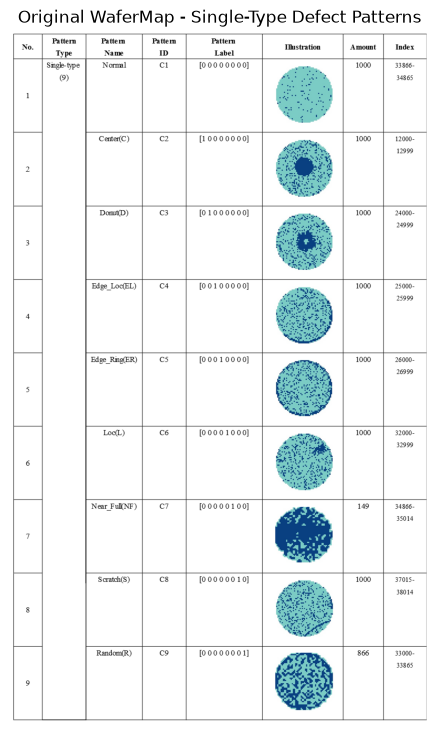

In [53]:

import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

url = (
    "https://raw.githubusercontent.com/"
    "Junliangwangdhu/WaferMap/master/"
    "Dataset%20Figure/Single-Type.png"
)

response = requests.get(url, timeout=20)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    img = Image.open(BytesIO(response.content))

    print("이미지 크기:", img.size)

    plt.figure(figsize=(15, 9))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Original WaferMap - Single-Type Defect Patterns")
    plt.show()
else:
    print("이미지를 불러오지 못했습니다.")


In [54]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score

# 1. 기존 WM-811K Baseline 불러오기
model = tf.keras.models.load_model(
    "wm811k_baseline_group.keras"
)

# 2. WaferGuard 이미지 전처리
X_eval = np.asarray(X_wafer, dtype=np.float32)

print("원본 픽셀 범위:", X_eval.min(), X_eval.max())

if X_eval.max() > 1.0:
    X_eval = np.clip(X_eval, 0, 2) / 2.0

if X_eval.ndim == 3:
    X_eval = X_eval[..., np.newaxis]

# 3. WaferGuard 라벨을 WM-811K 순서로 변경
y_eval = np.asarray(y_wafer, dtype=np.int32)
y_eval = y_eval[:, [0, 1, 2, 3, 4, 5, 7, 6]]

# 4. 결함 개수에 따라 분리
defect_count = y_eval.sum(axis=1)

single_mask = defect_count == 1
multi_mask = defect_count >= 2
normal_mask = defect_count == 0

print("\n=== 평가 데이터 구성 ===")
print("전체:", len(y_eval))
print("단일 결함:", single_mask.sum())
print("복합 결함:", multi_mask.sum())
print("Normal:", normal_mask.sum())

# 5. 학습 없이 예측
prob = model.predict(X_eval, batch_size=128, verbose=1)
pred = np.argmax(prob, axis=1)

# 6. 단일 결함 평가
single_true = np.argmax(y_eval[single_mask], axis=1)
single_pred = pred[single_mask]

single_acc = accuracy_score(single_true, single_pred)
single_macro_f1 = f1_score(
    single_true,
    single_pred,
    labels=np.arange(8),
    average="macro",
    zero_division=0
)

# 7. 복합 결함 평가
multi_true = y_eval[multi_mask]
multi_pred = pred[multi_mask]

top1_hit = multi_true[
    np.arange(len(multi_pred)),
    multi_pred
].mean()

# 8. 결과
print("\n=== WM-811K Baseline → WaferGuard ===")
print(f"단일 결함 Accuracy : {single_acc:.4f}")
print(f"단일 결함 Macro F1 : {single_macro_f1:.4f}")
print(f"복합 결함 Top-1 Hit Rate : {top1_hit:.4f}")

print("\n※ Normal은 모델에 Normal 출력 클래스가 없어")
print("  분류 정확도 계산에서 제외했습니다.")


원본 픽셀 범위: 0.0 3.0

=== 평가 데이터 구성 ===
전체: 38015
단일 결함: 7015
복합 결함: 30000
Normal: 1000
297/297 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step

=== WM-811K Baseline → WaferGuard ===
단일 결함 Accuracy : 0.7959
단일 결함 Macro F1 : 0.8000
복합 결함 Top-1 Hit Rate : 0.7962

※ Normal은 모델에 Normal 출력 클래스가 없어
  분류 정확도 계산에서 제외했습니다.


In [55]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

print("=== WaferGuard 단일 결함: 클래스별 성능 ===")

print(classification_report(
    single_true,
    single_pred,
    labels=range(8),
    target_names=wm_classes,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    single_true,
    single_pred,
    labels=range(8)
)

cm_df = pd.DataFrame(
    cm,
    index=wm_classes,
    columns=wm_classes
)

print("\n=== Confusion Matrix ===")
print("행: 실제 결함 / 열: 예측 결함")
display(cm_df)


=== WaferGuard 단일 결함: 클래스별 성능 ===
              precision    recall  f1-score   support

      Center     0.6967    0.9970    0.8202      1000
       Donut     0.9694    0.5710    0.7187      1000
    Edge-Loc     0.6305    0.3140    0.4192      1000
   Edge-Ring     0.6055    0.9990    0.7540      1000
         Loc     0.9265    0.9080    0.9172      1000
   Near-full     1.0000    0.8523    0.9203       149
      Random     0.9748    0.8938    0.9325       866
     Scratch     0.9440    0.8930    0.9178      1000

    accuracy                         0.7959      7015
   macro avg     0.8434    0.8035    0.8000      7015
weighted avg     0.8219    0.7959    0.7829      7015


=== Confusion Matrix ===
행: 실제 결함 / 열: 예측 결함


,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch
Center,997,0,0,0,3,0,0,0
Donut,418,571,0,0,11,0,0,0
Edge-Loc,0,0,314,651,2,0,0,33
Edge-Ring,0,0,1,999,0,0,0,0
Loc,0,0,75,0,908,0,0,17
Near-full,1,0,1,0,0,127,20,0
Random,12,18,24,0,35,0,774,3
Scratch,3,0,83,0,21,0,0,893


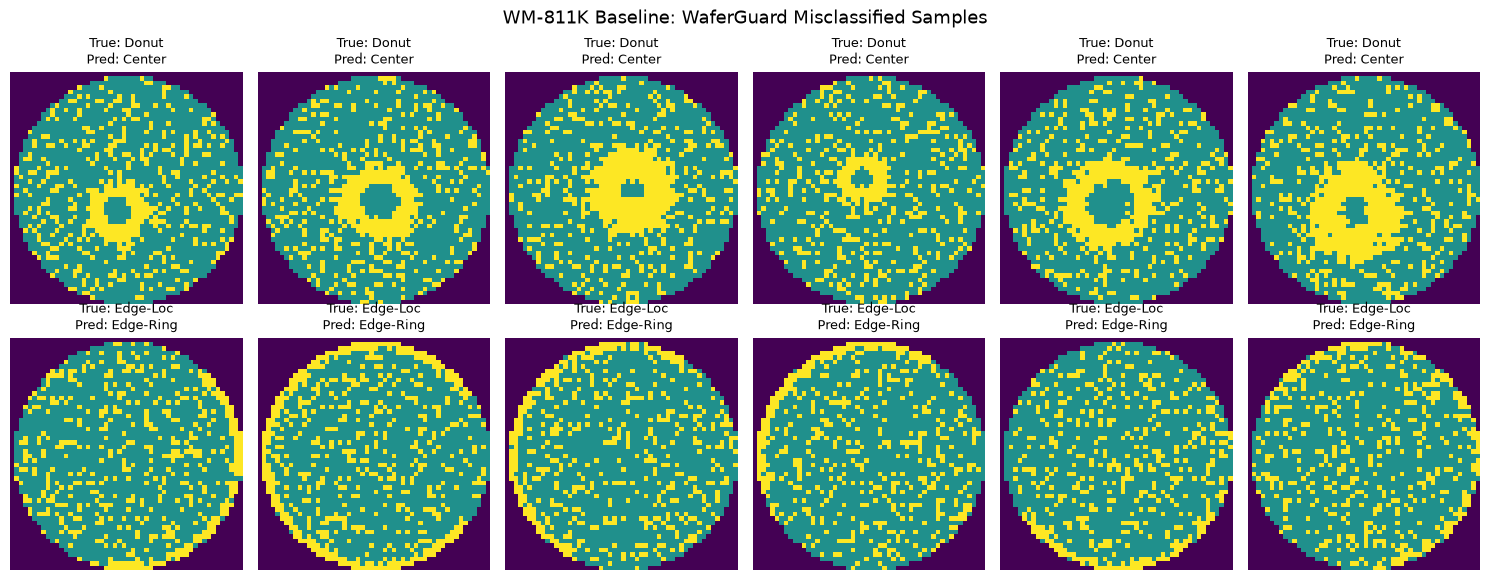

In [56]:

import numpy as np
import matplotlib.pyplot as plt

# 단일 결함 이미지의 원본 인덱스
single_indices = np.flatnonzero(single_mask)

# 분석할 오분류 조합
error_pairs = [
    ("Donut", "Center"),
    ("Edge-Loc", "Edge-Ring")
]

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for row, (true_name, pred_name) in enumerate(error_pairs):
    true_id = wm_classes.index(true_name)
    pred_id = wm_classes.index(pred_name)

    wrong_positions = np.flatnonzero(
        (single_true == true_id) &
        (single_pred == pred_id)
    )

    rng = np.random.default_rng(42)
    selected = rng.choice(
        wrong_positions,
        size=min(6, len(wrong_positions)),
        replace=False
    )

    for col, pos in enumerate(selected):
        original_idx = single_indices[pos]
        image = X_eval[original_idx].squeeze()

        axes[row, col].imshow(
            image,
            cmap="viridis",
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )
        axes[row, col].set_title(
            f"True: {true_name}\nPred: {pred_name}",
            fontsize=9
        )
        axes[row, col].axis("off")

    for col in range(len(selected), 6):
        axes[row, col].axis("off")

plt.suptitle(
    "WM-811K Baseline: WaferGuard Misclassified Samples",
    fontsize=13
)
plt.tight_layout()
plt.show()


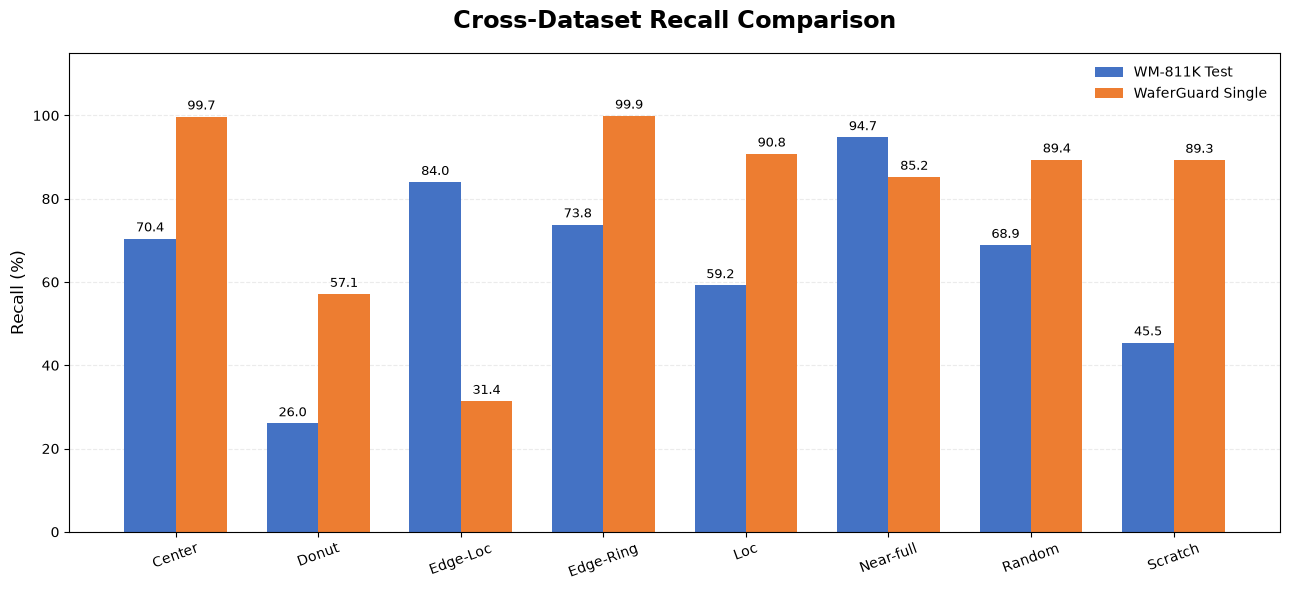

저장 완료: cross_dataset_recall_comparison.png


In [57]:

import numpy as np
import matplotlib.pyplot as plt

classes = [
    "Center", "Donut", "Edge-Loc", "Edge-Ring",
    "Loc", "Near-full", "Random", "Scratch"
]

wm_recall = np.array([
    70.43, 26.03, 83.98, 73.80,
    59.20, 94.74, 68.87, 45.45
])

wg_recall = np.array([
    99.70, 57.10, 31.40, 99.90,
    90.80, 85.23, 89.38, 89.30
])

x = np.arange(len(classes))
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))

bars1 = ax.bar(
    x - width/2, wm_recall, width,
    label="WM-811K Test",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width/2, wg_recall, width,
    label="WaferGuard Single",
    color="#ED7D31"
)

ax.bar_label(bars1, fmt="%.1f", padding=3, fontsize=9)
ax.bar_label(bars2, fmt="%.1f", padding=3, fontsize=9)

ax.set_title(
    "Cross-Dataset Recall Comparison",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Recall (%)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=20)
ax.set_ylim(0, 115)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "cross_dataset_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("저장 완료: cross_dataset_recall_comparison.png")


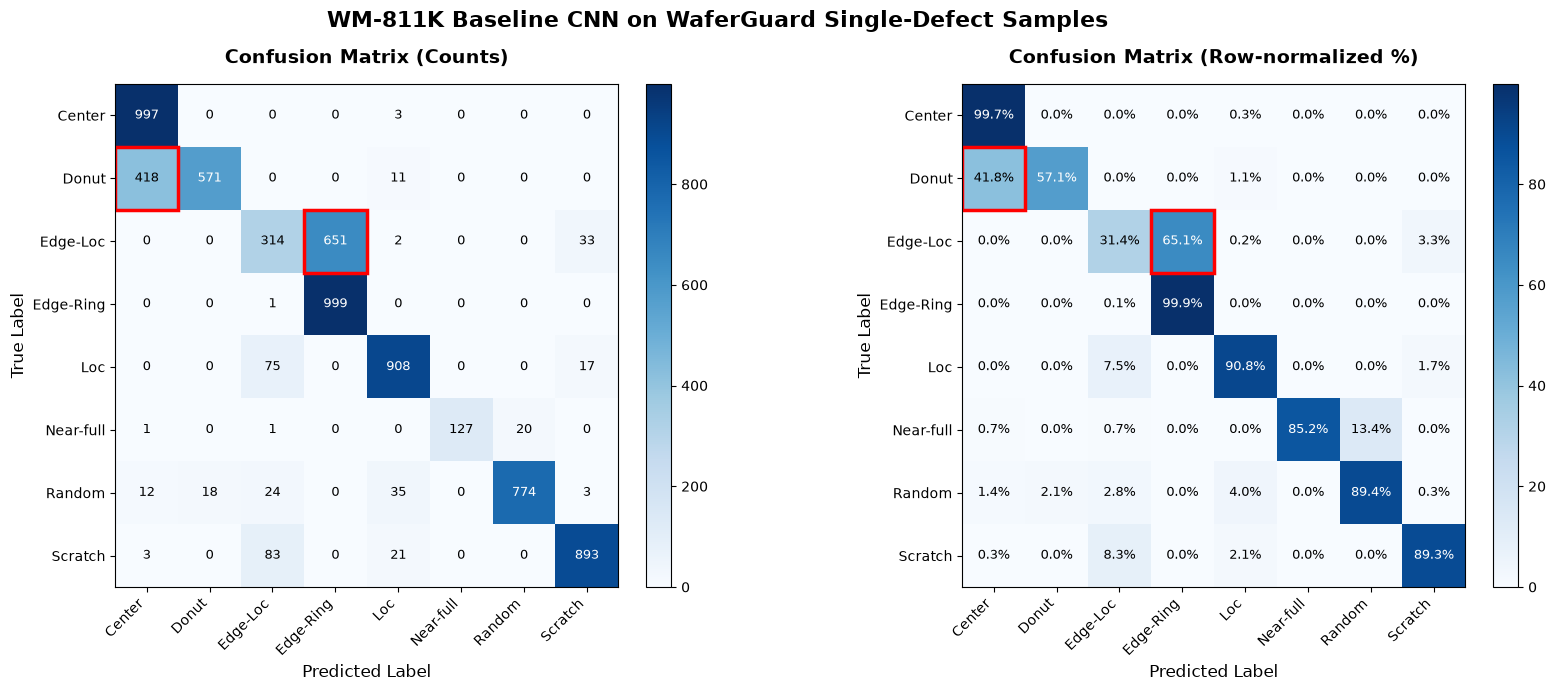

저장 완료: waferguard_confusion_matrix.png


In [58]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Confusion Matrix 생성
cm = confusion_matrix(
    single_true,
    single_pred,
    labels=np.arange(8)
)

# 행 기준 정규화 (실제 클래스별 비율)
cm_normalized = (
    cm / cm.sum(axis=1, keepdims=True) * 100
)

# 2. 그래프 생성
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

titles = [
    "Confusion Matrix (Counts)",
    "Confusion Matrix (Row-normalized %)"
]

matrices = [cm, cm_normalized]

for ax, matrix, title in zip(axes, matrices, titles):

    im = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=matrix.max()
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Predicted Label", fontsize=12)
    ax.set_ylabel("True Label", fontsize=12)

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))

    ax.set_xticklabels(wm_classes, rotation=45, ha="right")
    ax.set_yticklabels(wm_classes)

    # 셀 내부 수치 표시
    for i in range(8):
        for j in range(8):

            value = matrix[i, j]

            if title == titles[0]:
                label = f"{int(value)}"
            else:
                label = f"{value:.1f}%"

            color = (
                "white"
                if value > matrix.max() * 0.5
                else "black"
            )

            ax.text(
                j, i, label,
                ha="center",
                va="center",
                fontsize=9,
                color=color
            )

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# 3. 주요 오분류 위치 강조
from matplotlib.patches import Rectangle

error_pairs = [
    (1, 0),  # Donut -> Center
    (2, 3)   # Edge-Loc -> Edge-Ring
]

for ax in axes:
    for row, col in error_pairs:
        ax.add_patch(
            Rectangle(
                (col - 0.5, row - 0.5),
                1, 1,
                fill=False,
                edgecolor="red",
                linewidth=2.5
            )
        )

fig.suptitle(
    "WM-811K Baseline CNN on WaferGuard Single-Defect Samples",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# 4. 고해상도 이미지 저장
plt.savefig(
    "waferguard_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("저장 완료: waferguard_confusion_matrix.png")


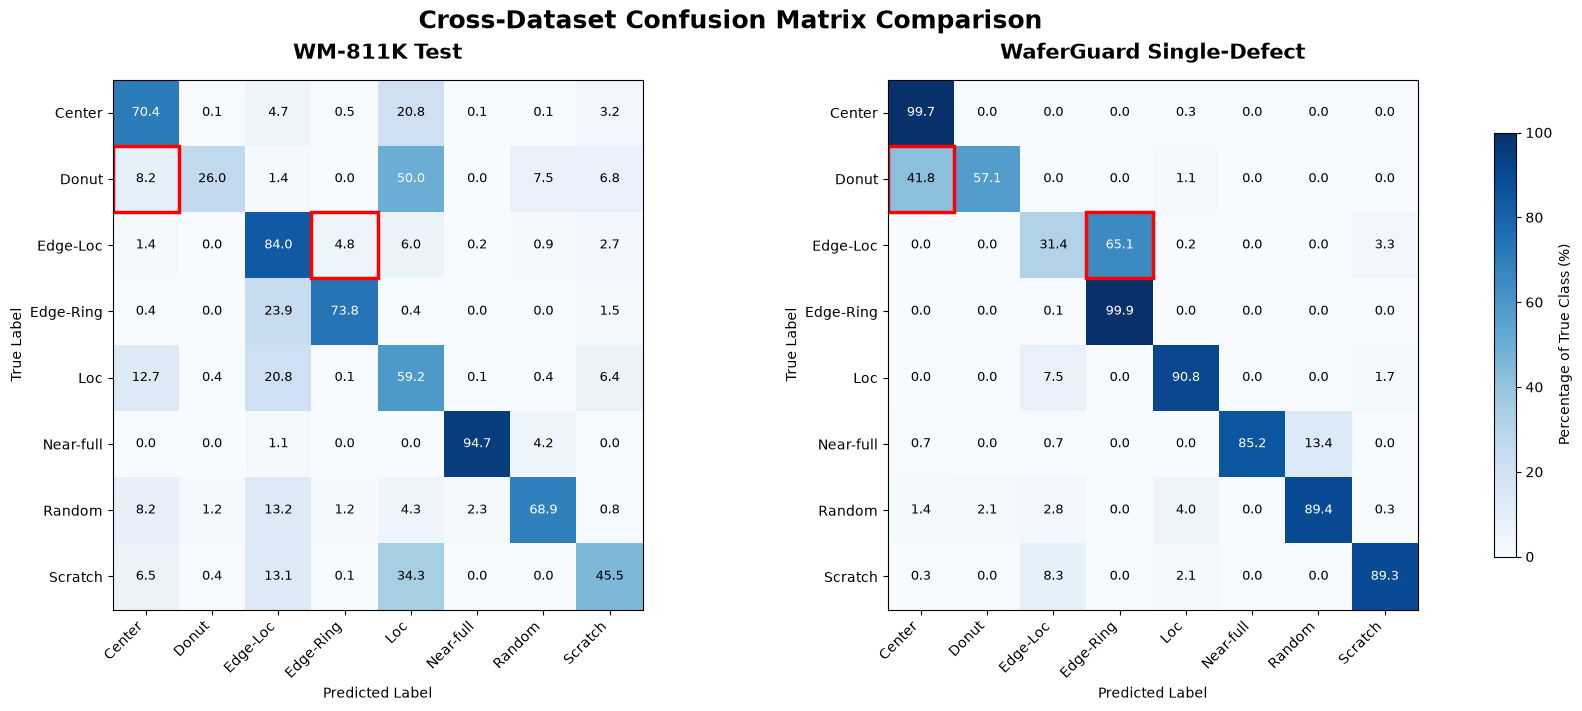

저장 완료: cross_dataset_confusion_comparison.png


In [60]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.metrics import confusion_matrix

# 기존 WM-811K Baseline Test 결과
wm_cm = np.array([
    [586, 1, 39, 4, 173, 1, 1, 27],
    [12, 38, 2, 0, 73, 0, 11, 10],
    [40, 1, 2328, 132, 166, 5, 25, 75],
    [4, 0, 269, 831, 5, 0, 0, 17],
    [250, 7, 411, 1, 1168, 2, 7, 127],
    [0, 0, 1, 0, 0, 90, 4, 0],
    [21, 3, 34, 3, 11, 6, 177, 2],
    [45, 3, 91, 1, 238, 0, 0, 315]
])

# WaferGuard 단일 결함 Confusion Matrix
wg_cm = confusion_matrix(
    single_true,
    single_pred,
    labels=np.arange(8)
)

# 행 기준 백분율 정규화
wm_pct = wm_cm / wm_cm.sum(axis=1, keepdims=True) * 100
wg_pct = wg_cm / wg_cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7),
    constrained_layout=True
)

datasets = [
    ("WM-811K Test", wm_pct),
    ("WaferGuard Single-Defect", wg_pct)
]

for ax, (title, matrix) in zip(axes, datasets):

    im = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(wm_classes, rotation=45, ha="right")
    ax.set_yticklabels(wm_classes)

    for i in range(8):
        for j in range(8):
            value = matrix[i, j]
            ax.text(
                j, i, f"{value:.1f}",
                ha="center", va="center",
                fontsize=9,
                color="white" if value >= 50 else "black"
            )

    # 주요 오분류 위치 표시
    for row, col in [(1, 0), (2, 3)]:
        ax.add_patch(
            Rectangle(
                (col - 0.5, row - 0.5),
                1, 1,
                fill=False,
                edgecolor="red",
                linewidth=2.5
            )
        )

fig.colorbar(
    im,
    ax=axes,
    shrink=0.8,
    label="Percentage of True Class (%)"
)

fig.suptitle(
    "Cross-Dataset Confusion Matrix Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.savefig(
    "cross_dataset_confusion_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("저장 완료: cross_dataset_confusion_comparison.png")


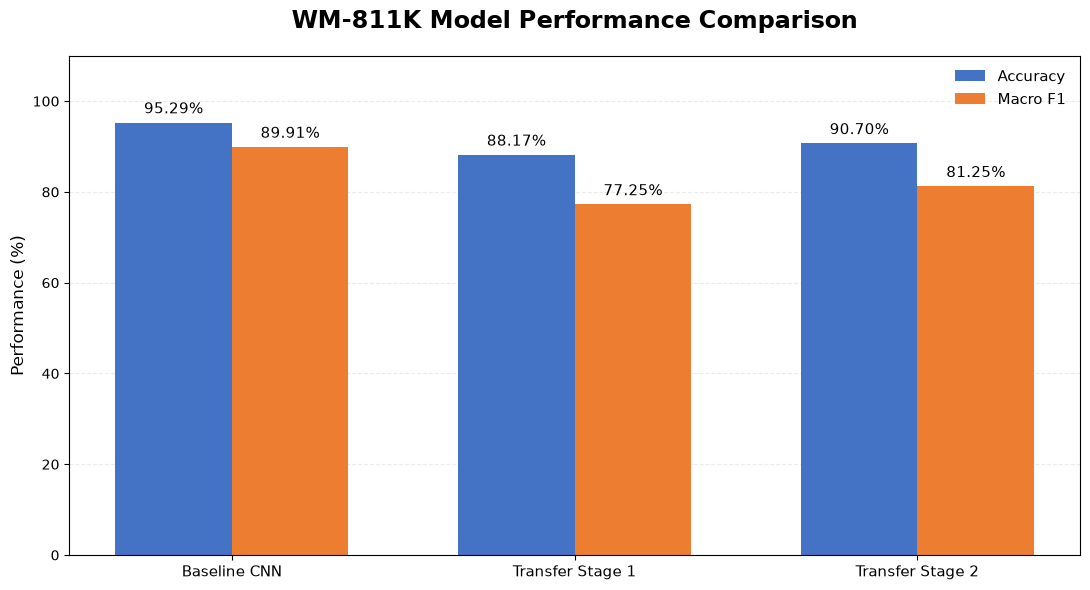

저장 완료: wm811k_model_comparison.png


In [61]:

import numpy as np
import matplotlib.pyplot as plt

# Lot-disjoint Validation 결과
models = [
    "Baseline CNN",
    "Transfer Stage 1",
    "Transfer Stage 2"
]

accuracy = np.array([95.29, 88.17, 90.70])
macro_f1 = np.array([89.91, 77.25, 81.25])

x = np.arange(len(models))
width = 0.34

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Accuracy",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width / 2,
    macro_f1,
    width,
    label="Macro F1",
    color="#ED7D31"
)

ax.bar_label(
    bars1, fmt="%.2f%%",
    padding=4, fontsize=11
)

ax.bar_label(
    bars2, fmt="%.2f%%",
    padding=4, fontsize=11
)

ax.set_title(
    "WM-811K Model Performance Comparison",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Performance (%)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0, 110)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=11
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "wm811k_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("저장 완료: wm811k_model_comparison.png")



=== Baseline CNN ===
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step
Test Accuracy : 0.7009
Test Macro F1 : 0.6702

=== Transfer Stage 2 ===
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step
Test Accuracy : 0.6390
Test Macro F1 : 0.6476


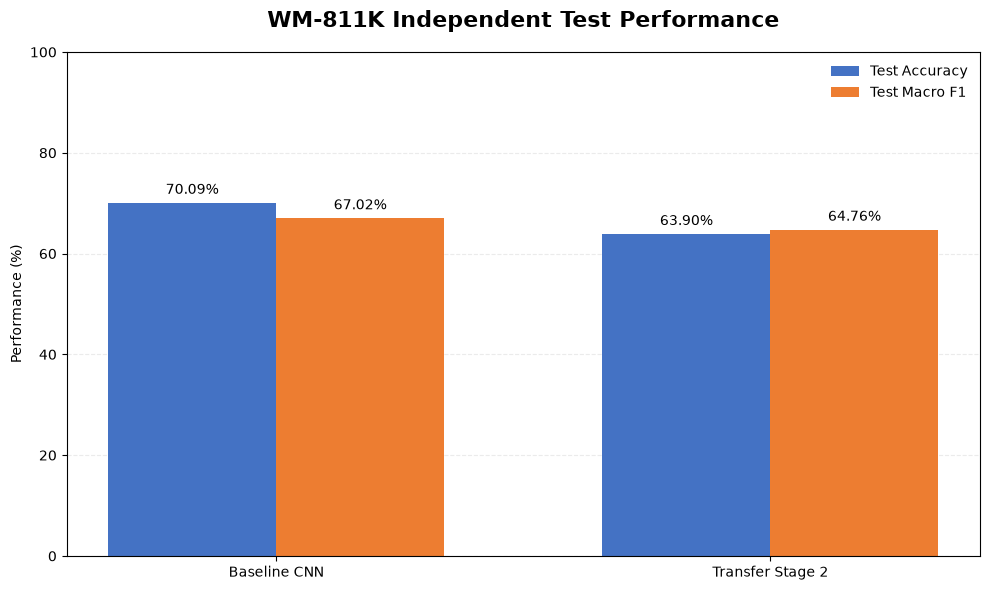


저장 완료: wm811k_test_model_comparison.png


In [62]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

# 1. 동일한 WM-811K Test 데이터 사용
models = {
    "Baseline CNN": "wm811k_baseline_group.keras",
    "Transfer Stage 2": "wm811k_group_stage2.keras"
}

results = {}

# 2. 모델별 Test 평가
for name, path in models.items():
    print(f"\n=== {name} ===")

    model = tf.keras.models.load_model(path)

    prob = model.predict(
        wm_X_test,
        batch_size=128,
        verbose=1
    )

    pred = np.argmax(prob, axis=1)

    acc = accuracy_score(wm_y_test, pred)
    macro_f1 = f1_score(
        wm_y_test,
        pred,
        labels=np.arange(8),
        average="macro",
        zero_division=0
    )

    results[name] = {
        "accuracy": acc * 100,
        "macro_f1": macro_f1 * 100
    }

    print(f"Test Accuracy : {acc:.4f}")
    print(f"Test Macro F1 : {macro_f1:.4f}")

# 3. 그래프 생성
names = list(results.keys())

accuracy = [
    results[name]["accuracy"]
    for name in names
]

macro_f1 = [
    results[name]["macro_f1"]
    for name in names
]

x = np.arange(len(names))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    accuracy,
    width,
    label="Test Accuracy",
    color="#4472C4"
)

bars2 = ax.bar(
    x + width / 2,
    macro_f1,
    width,
    label="Test Macro F1",
    color="#ED7D31"
)

ax.bar_label(bars1, fmt="%.2f%%", padding=4)
ax.bar_label(bars2, fmt="%.2f%%", padding=4)

ax.set_title(
    "WM-811K Independent Test Performance",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Performance (%)")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 100)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "wm811k_test_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n저장 완료: wm811k_test_model_comparison.png")


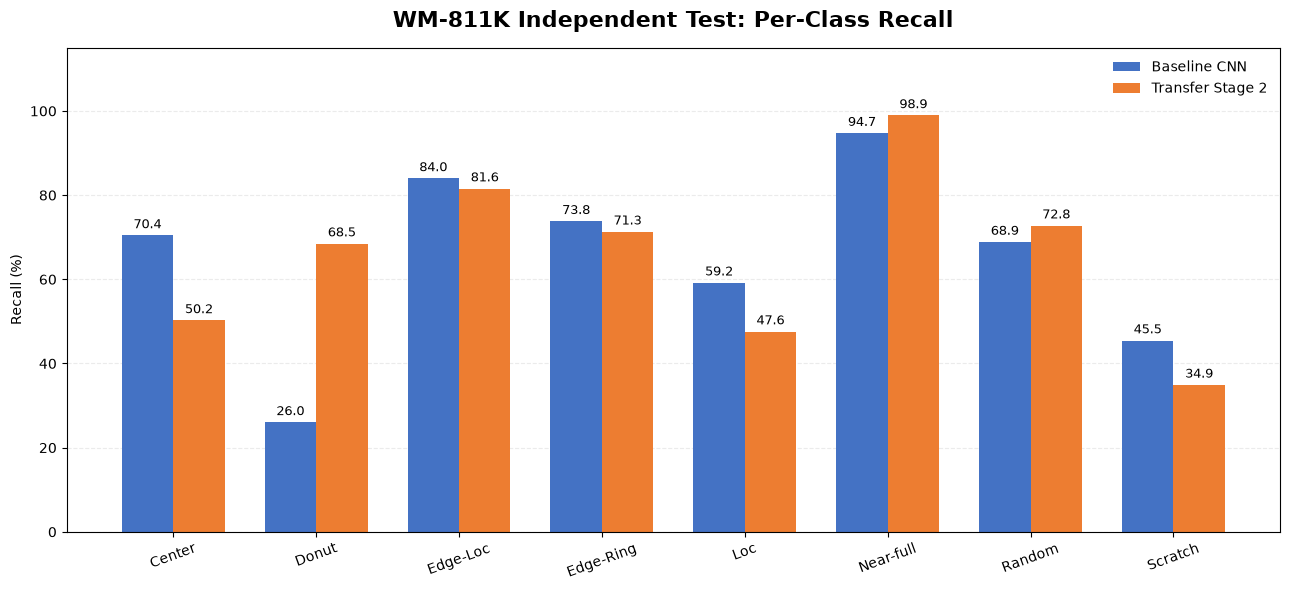


=== 클래스별 Recall (%) ===
Center     | Baseline:  70.43 | Transfer:  50.24 | 차이: +20.19%p
Donut      | Baseline:  26.03 | Transfer:  68.49 | 차이: -42.47%p
Edge-Loc   | Baseline:  83.98 | Transfer:  81.57 | 차이:  +2.42%p
Edge-Ring  | Baseline:  73.80 | Transfer:  71.31 | 차이:  +2.49%p
Loc        | Baseline:  59.20 | Transfer:  47.59 | 차이: +11.61%p
Near-full  | Baseline:  94.74 | Transfer:  98.95 | 차이:  -4.21%p
Random     | Baseline:  68.87 | Transfer:  72.76 | 차이:  -3.89%p
Scratch    | Baseline:  45.45 | Transfer:  34.92 | 차이: +10.53%p


In [63]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score

model_files = {
    "Baseline CNN": "wm811k_baseline_group.keras",
    "Transfer Stage 2": "wm811k_group_stage2.keras"
}

recall_results = {}

for name, path in model_files.items():
    model = tf.keras.models.load_model(path)
    predictions = model.predict(
        wm_X_test, batch_size=128, verbose=0
    ).argmax(axis=1)

    recall_results[name] = recall_score(
        wm_y_test,
        predictions,
        labels=np.arange(8),
        average=None,
        zero_division=0
    ) * 100

x = np.arange(8)
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))

for offset, (name, values), color in zip(
    [-width/2, width/2],
    recall_results.items(),
    ["#4472C4", "#ED7D31"]
):
    bars = ax.bar(
        x + offset, values, width,
        label=name, color=color
    )
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(wm_classes, rotation=20)
ax.set_ylim(0, 115)
ax.set_ylabel("Recall (%)")
ax.set_title(
    "WM-811K Independent Test: Per-Class Recall",
    fontsize=16, fontweight="bold", pad=15
)
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "wm811k_test_class_recall_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("\n=== 클래스별 Recall (%) ===")
for i, cls in enumerate(wm_classes):
    baseline = recall_results["Baseline CNN"][i]
    transfer = recall_results["Transfer Stage 2"][i]
    print(
        f"{cls:10s} | Baseline: {baseline:6.2f} | "
        f"Transfer: {transfer:6.2f} | "
        f"차이: {baseline-transfer:+6.2f}%p"
    )


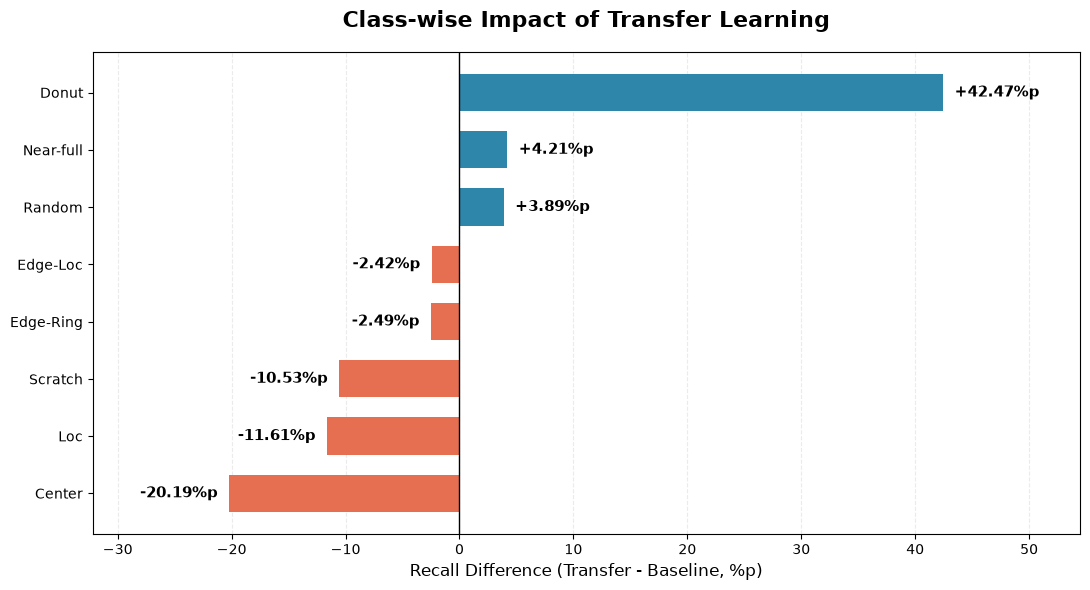

저장 완료: transfer_learning_class_impact.png


In [64]:

import numpy as np
import matplotlib.pyplot as plt

# 이전 셀에서 계산한 Recall 사용
baseline = recall_results["Baseline CNN"]
transfer = recall_results["Transfer Stage 2"]

# Transfer - Baseline
difference = transfer - baseline

# 차이가 큰 순서대로 정렬
order = np.argsort(difference)
classes_sorted = np.array(wm_classes)[order]
diff_sorted = difference[order]

colors = [
    "#2E86AB" if value > 0 else "#E76F51"
    for value in diff_sorted
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    classes_sorted,
    diff_sorted,
    color=colors,
    height=0.65
)

ax.axvline(0, color="black", linewidth=1)

for bar, value in zip(bars, diff_sorted):
    x = bar.get_width()

    ax.text(
        x + (1 if x >= 0 else -1),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.2f}%p",
        va="center",
        ha="left" if x >= 0 else "right",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(
    min(diff_sorted) - 12,
    max(diff_sorted) + 12
)

ax.set_xlabel(
    "Recall Difference (Transfer - Baseline, %p)",
    fontsize=12
)

ax.set_title(
    "Class-wise Impact of Transfer Learning",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "transfer_learning_class_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("저장 완료: transfer_learning_class_impact.png")


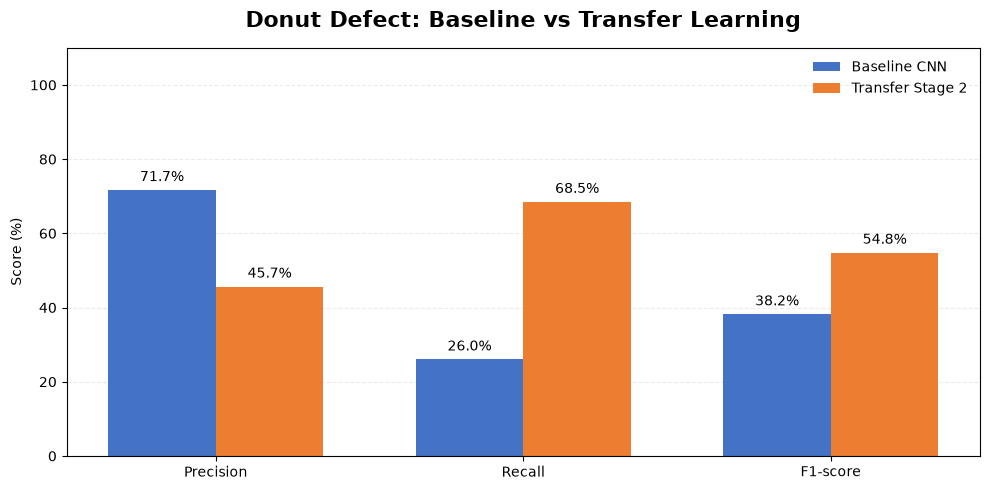


=== Donut 성능 비교 ===
Baseline CNN       | Precision: 71.70% | Recall: 26.03% | F1: 38.19%
Transfer Stage 2   | Precision: 45.66% | Recall: 68.49% | F1: 54.79%


In [65]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support

model_files = {
    "Baseline CNN": "wm811k_baseline_group.keras",
    "Transfer Stage 2": "wm811k_group_stage2.keras"
}

metrics_by_model = {}

for name, path in model_files.items():
    model = tf.keras.models.load_model(path)

    y_pred = model.predict(
        wm_X_test,
        batch_size=128,
        verbose=0
    ).argmax(axis=1)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            wm_y_test,
            y_pred,
            labels=np.arange(8),
            zero_division=0
        )
    )

    metrics_by_model[name] = np.column_stack([
        precision, recall, f1
    ]) * 100

# Donut만 우선 상세 비교
donut_idx = wm_classes.index("Donut")
metric_names = ["Precision", "Recall", "F1-score"]

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(3)
width = 0.35

for offset, (name, values), color in zip(
    [-width/2, width/2],
    metrics_by_model.items(),
    ["#4472C4", "#ED7D31"]
):
    bars = ax.bar(
        x + offset,
        values[donut_idx],
        width,
        label=name,
        color=color
    )
    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=4
    )

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 110)
ax.set_ylabel("Score (%)")

ax.set_title(
    "Donut Defect: Baseline vs Transfer Learning",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "donut_precision_recall_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n=== Donut 성능 비교 ===")
for name, values in metrics_by_model.items():
    p, r, f = values[donut_idx]
    print(
        f"{name:18s} | "
        f"Precision: {p:.2f}% | "
        f"Recall: {r:.2f}% | "
        f"F1: {f:.2f}%"
    )


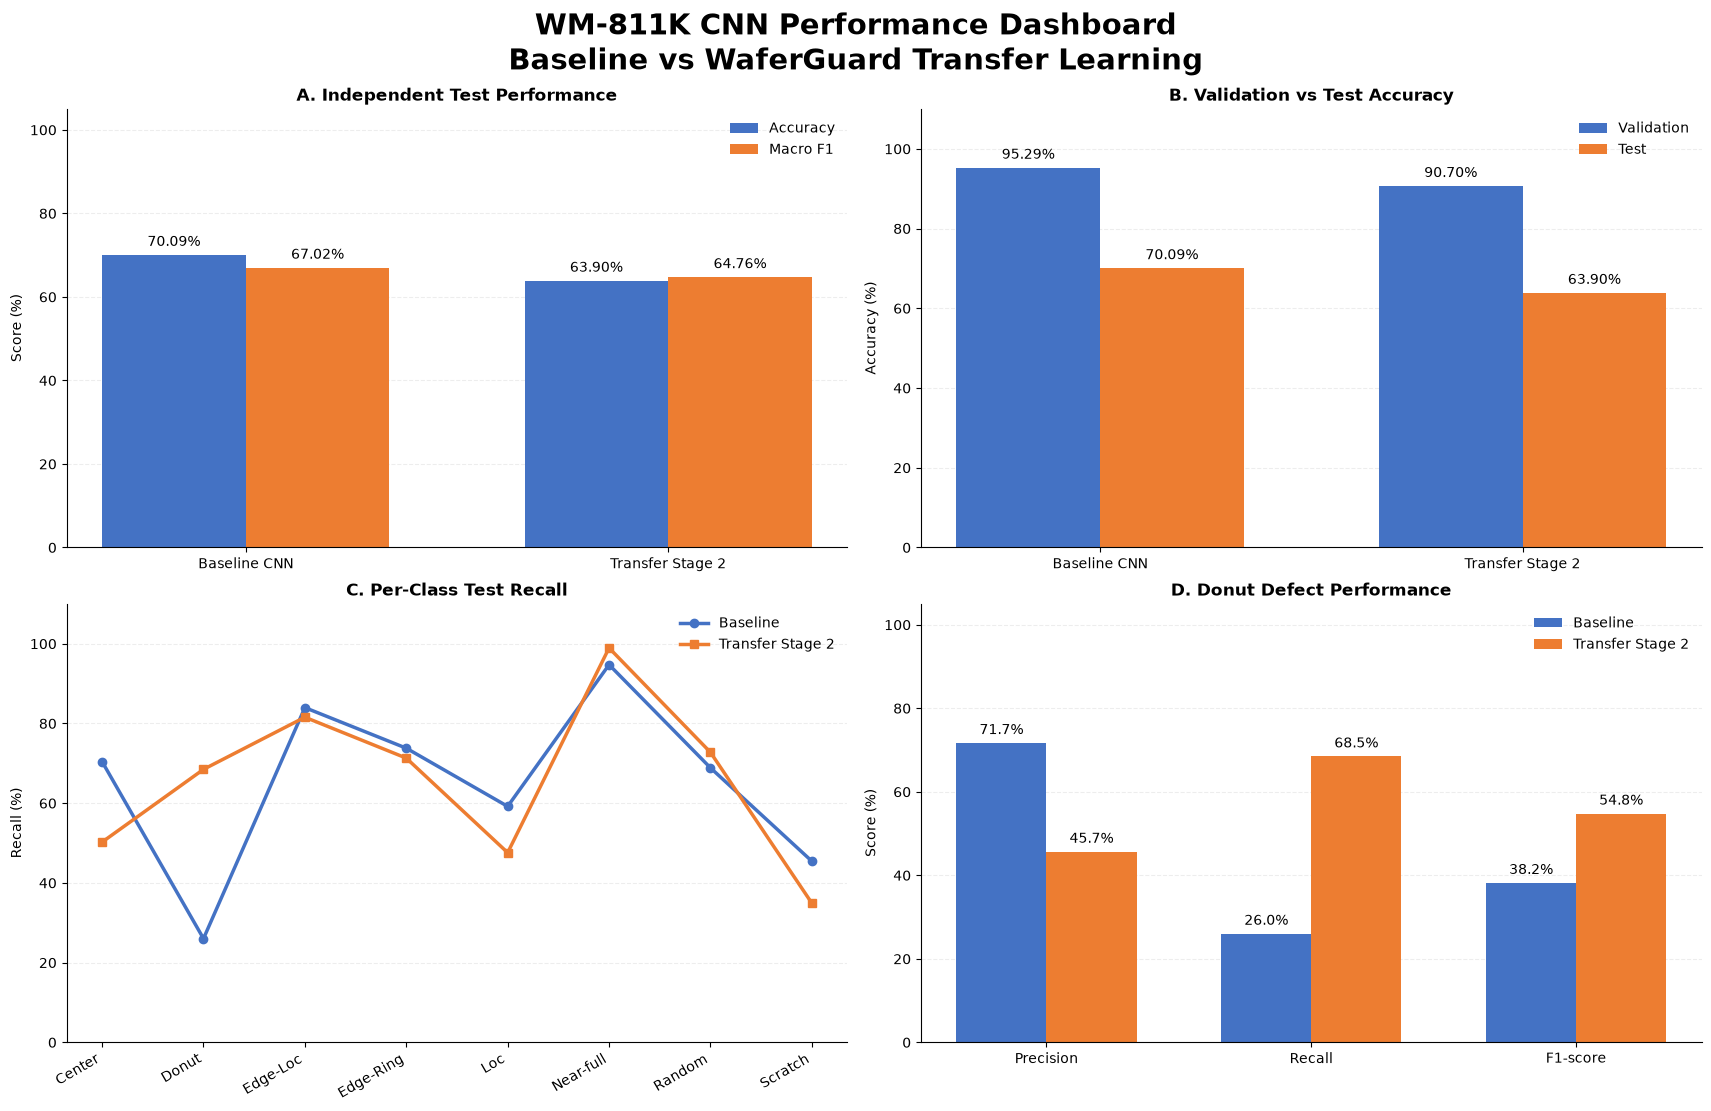

대시보드 생성 완료
PNG: WM811K_CNN_Performance_Dashboard.png
PDF: WM811K_CNN_Performance_Dashboard.pdf


In [66]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ==========================================
# 1. 기존 실험 결과
# ==========================================

classes = [
    "Center", "Donut", "Edge-Loc", "Edge-Ring",
    "Loc", "Near-full", "Random", "Scratch"
]

models = ["Baseline CNN", "Transfer Stage 2"]

# Lot-disjoint Validation
val_acc = [95.29, 90.70]

# Independent Test
test_acc = [70.09, 63.90]
test_f1 = [67.02, 64.76]

# Test Recall
baseline_recall = [
    70.43, 26.03, 83.98, 73.80,
    59.20, 94.74, 68.87, 45.45
]

transfer_recall = [
    50.24, 68.49, 81.57, 71.31,
    47.59, 98.95, 72.76, 34.92
]

# Donut: Precision, Recall, F1
donut_baseline = [71.70, 26.03, 38.19]
donut_transfer = [45.66, 68.49, 54.79]

BLUE = "#4472C4"
ORANGE = "#ED7D31"

# ==========================================
# 2. 대시보드 레이아웃
# ==========================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 11),
    constrained_layout=True
)

fig.suptitle(
    "WM-811K CNN Performance Dashboard\n"
    "Baseline vs WaferGuard Transfer Learning",
    fontsize=21,
    fontweight="bold"
)

def style_axis(ax):
    ax.grid(axis="y", linestyle="--", alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ==========================================
# 3. 좌상단: Independent Test
# ==========================================

ax = axes[0, 0]
x = np.arange(2)
w = 0.34

b1 = ax.bar(
    x - w/2, test_acc, w,
    color=BLUE, label="Accuracy"
)
b2 = ax.bar(
    x + w/2, test_f1, w,
    color=ORANGE, label="Macro F1"
)

ax.bar_label(b1, fmt="%.2f%%", padding=4)
ax.bar_label(b2, fmt="%.2f%%", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_title(
    "A. Independent Test Performance",
    fontweight="bold"
)
ax.legend(frameon=False)
style_axis(ax)

# ==========================================
# 4. 우상단: Validation vs Test
# ==========================================

ax = axes[0, 1]

b1 = ax.bar(
    x - w/2, val_acc, w,
    color=BLUE, label="Validation"
)
b2 = ax.bar(
    x + w/2, test_acc, w,
    color=ORANGE, label="Test"
)

ax.bar_label(b1, fmt="%.2f%%", padding=4)
ax.bar_label(b2, fmt="%.2f%%", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 110)
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "B. Validation vs Test Accuracy",
    fontweight="bold"
)
ax.legend(frameon=False)
style_axis(ax)

# ==========================================
# 5. 좌하단: 클래스별 Recall
# ==========================================

ax = axes[1, 0]
x8 = np.arange(8)

ax.plot(
    x8, baseline_recall,
    marker="o", linewidth=2.5,
    color=BLUE, label="Baseline"
)

ax.plot(
    x8, transfer_recall,
    marker="s", linewidth=2.5,
    color=ORANGE, label="Transfer Stage 2"
)

ax.set_xticks(x8)
ax.set_xticklabels(
    classes, rotation=30, ha="right"
)
ax.set_ylim(0, 110)
ax.set_ylabel("Recall (%)")
ax.set_title(
    "C. Per-Class Test Recall",
    fontweight="bold"
)
ax.legend(frameon=False)
style_axis(ax)

# ==========================================
# 6. 우하단: Donut 상세 분석
# ==========================================

ax = axes[1, 1]
x3 = np.arange(3)

b1 = ax.bar(
    x3 - w/2, donut_baseline, w,
    color=BLUE, label="Baseline"
)
b2 = ax.bar(
    x3 + w/2, donut_transfer, w,
    color=ORANGE, label="Transfer Stage 2"
)

ax.bar_label(b1, fmt="%.1f%%", padding=4)
ax.bar_label(b2, fmt="%.1f%%", padding=4)

ax.set_xticks(x3)
ax.set_xticklabels(
    ["Precision", "Recall", "F1-score"]
)
ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_title(
    "D. Donut Defect Performance",
    fontweight="bold"
)
ax.legend(frameon=False)
style_axis(ax)

# ==========================================
# 7. 파일 저장
# ==========================================

fig.savefig(
    "WM811K_CNN_Performance_Dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "WM811K_CNN_Performance_Dashboard.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("대시보드 생성 완료")
print("PNG: WM811K_CNN_Performance_Dashboard.png")
print("PDF: WM811K_CNN_Performance_Dashboard.pdf")


In [67]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score

# 기존 전이학습 Stage 2 모델
transfer_model = tf.keras.models.load_model(
    "wm811k_group_stage2.keras"
)

# WaferGuard 전체 예측 (재학습 없음)
transfer_prob = transfer_model.predict(
    X_eval,
    batch_size=128,
    verbose=1
)

transfer_pred = np.argmax(transfer_prob, axis=1)

# 단일 결함 평가
transfer_single_true = np.argmax(
    y_eval[single_mask], axis=1
)
transfer_single_pred = transfer_pred[single_mask]

transfer_single_acc = accuracy_score(
    transfer_single_true,
    transfer_single_pred
)

transfer_single_f1 = f1_score(
    transfer_single_true,
    transfer_single_pred,
    labels=np.arange(8),
    average="macro",
    zero_division=0
)

# 복합 결함 평가
transfer_multi_true = y_eval[multi_mask]
transfer_multi_pred = transfer_pred[multi_mask]

transfer_top1_hit = transfer_multi_true[
    np.arange(len(transfer_multi_pred)),
    transfer_multi_pred
].mean()

# 결과 비교
print("\n=== WaferGuard 평가 결과 ===")
print(f"{'Metric':<25} {'Baseline':>12} {'Transfer':>12}")
print("-" * 52)
print(
    f"{'Single Accuracy':<25} "
    f"{0.7959:>12.4f} {transfer_single_acc:>12.4f}"
)
print(
    f"{'Single Macro F1':<25} "
    f"{0.8000:>12.4f} {transfer_single_f1:>12.4f}"
)
print(
    f"{'Multi Top-1 Hit':<25} "
    f"{0.7962:>12.4f} {transfer_top1_hit:>12.4f}"
)


297/297 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step

=== WaferGuard 평가 결과 ===
Metric                        Baseline     Transfer
----------------------------------------------------
Single Accuracy                 0.7959       0.7246
Single Macro F1                 0.8000       0.7184
Multi Top-1 Hit                 0.7962       0.5643


In [68]:

import os

required_vars = [
    "wm_X_test",
    "wm_y_test",
    "wm_classes",
    "X_wafer",
    "y_wafer"
]

print("=== 기존 커널 데이터 확인 ===")

for name in required_vars:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {getattr(value, 'shape', '존재')}")
    else:
        print(f"{name}: 없음")

print("\nWaferGuard 모델:",
      os.path.exists("waferguard_pretrained.keras"))


=== 기존 커널 데이터 확인 ===
wm_X_test: (7894, 52, 52, 1)
wm_y_test: (7894,)
wm_classes: 존재
X_wafer: (38015, 52, 52)
y_wafer: (38015, 8)

WaferGuard 모델: True


In [69]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. WaferGuard 사전학습 모델 불러오기
waferguard_model = tf.keras.models.load_model(
    "waferguard_pretrained.keras"
)

# 2. WM-811K Test 데이터 직접 예측
# 추가 학습이나 Fine-tuning 없음
wg_prob = waferguard_model.predict(
    wm_X_test,
    batch_size=128,
    verbose=1
)

# 3. WaferGuard 출력 순서 → WM-811K 순서
# WaferGuard: ... Near-full, Scratch, Random
# WM-811K:   ... Near-full, Random, Scratch
wg_prob_wm_order = wg_prob[:, [0, 1, 2, 3, 4, 5, 7, 6]]

# 4. 가장 높은 확률의 결함 선택
wg_pred = np.argmax(wg_prob_wm_order, axis=1)

# 5. 성능 평가
wg_acc = accuracy_score(wm_y_test, wg_pred)

wg_macro_f1 = f1_score(
    wm_y_test,
    wg_pred,
    average="macro",
    zero_division=0
)

print("\n=== WaferGuard CNN → WM-811K Zero-shot ===")
print(f"Test samples : {len(wm_y_test):,}")
print(f"Accuracy     : {wg_acc:.4f}")
print(f"Macro F1     : {wg_macro_f1:.4f}")

print("\n=== Classification Report ===")
print(
    classification_report(
        wm_y_test,
        wg_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)

print("\n=== Confusion Matrix ===")
print(confusion_matrix(
    wm_y_test,
    wg_pred,
    labels=np.arange(8)
))


62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step

=== WaferGuard CNN → WM-811K Zero-shot ===
Test samples : 7,894
Accuracy     : 0.3063
Macro F1     : 0.2491

=== Classification Report ===
              precision    recall  f1-score   support

      Center     0.1515    0.0180    0.0322       832
       Donut     0.5714    0.0274    0.0523       146
    Edge-Loc     0.4393    0.5981    0.5066      2772
   Edge-Ring     0.9451    0.3979    0.5600      1126
         Loc     0.2996    0.0405    0.0714      1973
   Near-full     0.5786    0.8526    0.6894        95
      Random     0.0426    0.5097    0.0786       257
     Scratch     0.0172    0.0014    0.0027       693

    accuracy                         0.3063      7894
   macro avg     0.3807    0.3057    0.2491      7894
weighted avg     0.4004    0.3063    0.2911      7894


=== Confusion Matrix ===
[[  15    0  521    1    2    3  290    0]
 [  11    4   14    1    4    1  108    3]
 [  12    1 1658   23  110   24  935    9]
 [   6    0  5

In [70]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Stage 1 모델 불러오기
stage1_model = tf.keras.models.load_model(
    "wm811k_group_stage1.keras"
)

# 동일한 WM-811K Test 데이터 예측
stage1_prob = stage1_model.predict(
    wm_X_test,
    batch_size=128,
    verbose=1
)

stage1_pred = np.argmax(stage1_prob, axis=1)

# 성능 계산
stage1_acc = accuracy_score(wm_y_test, stage1_pred)
stage1_f1 = f1_score(
    wm_y_test,
    stage1_pred,
    average="macro",
    zero_division=0
)

print("\n=== WM-811K Test 모델 비교 ===")
print(f"{'Model':<24} {'Accuracy':>12} {'Macro F1':>12}")
print("-" * 50)
print(f"{'WaferGuard Zero-shot':<24} {wg_acc:>12.4f} {wg_macro_f1:>12.4f}")
print(f"{'Transfer Stage 1':<24} {stage1_acc:>12.4f} {stage1_f1:>12.4f}")
print(f"{'Transfer Stage 2':<24} {0.6390:>12.4f} {0.6476:>12.4f}")
print(f"{'WM-811K Baseline':<24} {0.7009:>12.4f} {0.6702:>12.4f}")

print("\n=== Stage 1 Classification Report ===")
print(
    classification_report(
        wm_y_test,
        stage1_pred,
        labels=np.arange(8),
        target_names=wm_classes,
        digits=4,
        zero_division=0
    )
)


62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step

=== WM-811K Test 모델 비교 ===
Model                        Accuracy     Macro F1
--------------------------------------------------
WaferGuard Zero-shot           0.3063       0.2491
Transfer Stage 1               0.5918       0.6000
Transfer Stage 2               0.6390       0.6476
WM-811K Baseline               0.7009       0.6702

=== Stage 1 Classification Report ===
              precision    recall  f1-score   support

      Center     0.4037    0.3654    0.3836       832
       Donut     0.4123    0.5959    0.4874       146
    Edge-Loc     0.6492    0.7983    0.7161      2772
   Edge-Ring     0.8861    0.7256    0.7979      1126
         Loc     0.4479    0.4161    0.4314      1973
   Near-full     0.9300    0.9789    0.9538        95
      Random     0.7942    0.7510    0.7720       257
     Scratch     0.3404    0.2078    0.2581       693

    accuracy                         0.5918      7894
   macro avg     0.6080    0.6049    0.6000  